# Phase 24 — Narrowed Benefit-Aware Refinement Architecture + Pre-Registered Development Protocol

### A DESIGN-ONLY specification, written BEFORE any implementation, training or evaluation

| Item | Value |
|---|---|
| Phase | 24 — Narrowed Benefit-Aware Refinement Architecture |
| Canonical folder | `notebooks/phasewise/phase_24_architecture_spec/` |
| Method name (frozen, provisional) | `RA-MedFiLM-BARR` — Resource-Aware MedFiLM with Benefit-Aware Refinement Routing |
| Architecture id | `ra_medfilm_barr_narrowed_v1` |
| Purpose | Answer **"what exactly will we build, train and evaluate later?"** — nothing more |
| Predecessor terminal | `PHASE23_REVIEWER_VISUALS_COMPLETE__SCIENCE_UNCHANGED__PHASE24_NARROWED_SPEC_ELIGIBLE_NOT_STARTED` |
| Phase-23 novelty basis | `PARTIALLY_OCCUPIED__NARROWER_NOVELTY_POSSIBLE` (max claim **Level 2**; strongest residual = axis **D**) |
| New training | **NONE** |
| Segmentation inference | **NONE** |
| Benefit-router inference | **NONE** |
| Router-holdout outcomes read | **0** |
| TEST | **CLOSED** — 0 image reads, 0 mask reads, 0 inference, 0 visualizations |
| Phase 25 | **ELIGIBLE, NOT STARTED** |
| Terminal state | `PHASE24_NARROWED_BENEFIT_AWARE_REFINEMENT_SPEC_COMPLETE__PHASE25_ELIGIBLE_NOT_STARTED` |

**What Phase 24 is.** A *pre-registration specification*. It fixes the architecture, the
contracts, the data protocol, the comparator set, the ablations, the statistics and the
success/failure criteria **before** anything is built, so that later experiments cannot
be retro-fitted to a convenient narrative.

**What Phase 24 is NOT.** It is **NOT** an implementation, **NOT** a training phase, and it
does **NOT** produce any experimental result. Every numeric target below is a **DESIGN
TARGET** and is explicitly marked **unmeasured**. The frozen method name may not be used to
assert a finding.

## 2. Entry gate (fail-closed)

Before writing any Phase-24 artifact, every predecessor identity and governance lock is
verified. The gate is **fail-closed**: a single failed check aborts with
`PHASE24_NARROWED_SPEC_BLOCKED__REDESIGN_REQUIRED`. It never repairs frozen science.

In [1]:
import json, hashlib, pathlib
import pandas as pd

ROOT = pathlib.Path(r"D:/Softfors/jup")
AUD = ROOT / "reports" / "audits"
TAB = ROOT / "reports" / "tables"

from IPython.display import Image, Markdown, display

def _j(p):
    p = pathlib.Path(p)
    return json.loads(p.read_text(encoding="utf-8")) if p.exists() else {}

def sty(df, uid, fmt=None):
    """Deterministic pandas Styler (fixed uuid so builds are byte-identical)."""
    s = df.style
    if fmt:
        s = s.format(fmt)
    return s.set_uuid(uid)

FIG = ROOT / "reports" / "figures" / "phase24_architecture_spec"

def fig(name, caption=None):
    """Embed a Phase-24 DESIGN figure as a REAL inline image output.

    FAIL-CLOSED: raises if the figure is missing, empty, or not a valid PNG.
    Figures are built by scripts/analysis/build_phase24_figures.py from the frozen
    Phase-24 design tables/audits only.
    """
    p = FIG / name
    if not p.exists():
        raise FileNotFoundError(f"FAIL-CLOSED: required Phase-24 figure missing: {p}")
    raw = p.read_bytes()
    if not raw.startswith(b"\x89PNG\r\n\x1a\n"):
        raise ValueError(f"FAIL-CLOSED: not a PNG: {p}")
    if len(raw) < 2048:
        raise ValueError(f"FAIL-CLOSED: suspiciously small PNG ({len(raw)}B): {p}")
    _img = Image(data=raw, format="png", embed=True)
    return display(_img) if caption is None else display(Markdown(f"**{caption}**"), _img)

gate = _j(AUD / "phase24_entry_gate.json")
print("entry gate verdict  :", gate.get("verdict"))
print("checks              :", f"{gate.get('n_passed')}/{gate.get('n_checks')}")
print("no training         :", gate.get("no_training"))
print("no segmentation inf :", gate.get("no_segmentation_inference"))
print("no router inf       :", gate.get("no_router_inference"))
print("TEST reads          :", gate.get("test_reads"))
print("phase24 started     :", gate.get("phase24_started"))
print("phase25 started     :", gate.get("phase25_started"))
print()
for k, v in gate.get("bindings", {}).items():
    print(f"  {k:34s} {str(v)[:24]}")

entry gate verdict  : PHASE24_ENTRY_GATE_PASS
checks              : 27/27
no training         : True
no segmentation inf : True
no router inf       : True
TEST reads          : 0
phase24 started     : True
phase25 started     : False

  phase21_best_pt_sha256             286689fdd5c63ad75a383151
  phase22_freeze_sha256              9a0aa2f8c1a2850770fb09f2
  phase22_protocol_sha256            9d620d6c85276e1a9a086ec6
  phase23_notebook_sha256            e9f78ccefd96abad742fa557


## 3. Hard boundaries respected by this notebook

| Boundary | Status in Phase 24 |
|---|---|
| NO TRAINING | respected — 0 optimizers, 0 backward passes, 0 checkpoint writes |
| NO SEGMENTATION INFERENCE | respected — 0 model forward calls |
| NO BENEFIT-ROUTER FORWARD CALL | respected — the router does not exist yet |
| NO REFINEMENT EXECUTION | respected — `R_psi` does not exist yet |
| NO HOLDOUT OUTCOME INSPECTION | respected — `ROUTER_HOLDOUT` outcomes read = 0 |
| NO TEST ACCESS | respected — TEST remains CLOSED |
| NO SUPERVISED RESULT CHANGE | respected — the 808-case VAL stays `SECONDARY / CONTINUITY DEVELOPMENT BENCHMARK` |
| NO LITERATURE RERUN | respected — the prior-art table is a design input, not a new search |
| DO NOT START PHASE 25 | respected — 0 modules of 25A–25G started |

## 4. The narrowed contribution (Phase-23 residual, adopted verbatim)

Phase 23 found the individual primitives **occupied**. Adopted without re-litigation:

| Axis | Phase-23 status |
|---|---|
| A — problem formulation | `OCCUPIED` |
| B — learning target | `NOT_OCCUPIED_AS_A_LEARNED_SEGMENTATION_TARGET` |
| C — decision mechanism | `PARTIALLY_OCCUPIED` |
| D — system integration | `NOT_OCCUPIED_AS_A_COMBINATION` — **strongest residual** |

**The single novelty-bearing component** is therefore, and only:

> a **learned, GT-free, pre-refinement** predictor of the **paired refinement gain**, used to
> route an **optional** regional refinement, with a **preservation fallback** and an
> **explicit resource-cost term**, inside **one shared multi-domain medical-segmentation system**.

In [2]:
nov = _j(AUD / "phase24_novelty_boundary.json")
print("overall label      :", nov.get("phase23_overall_label"))
print("max claim level    :", nov.get("phase23_maximum_defensible_claim_level"))
print("strongest residual :", nov.get("phase23_axes", {}).get("strongest_residual"))
print("claim level now    :", nov.get("claim_level_permitted_now"))
print("level 3 status     :", nov.get("level_3_status"))
print()
print("novelty-bearing component:")
print("  ", nov.get("novelty_bearing_component"))
print()
print("explicit non-claims:")
for c in nov.get("explicit_non_claims", []):
    print("   -", c)

overall label      : PARTIALLY_OCCUPIED__NARROWER_NOVELTY_POSSIBLE
max claim level    : 2
strongest residual : D
claim level now    : Level 0/1 (investigate / propose). Level 2 only after empirical support, scoped strictly to the integrated residual.
level 3 status     : NOT_SUPPORTED

novelty-bearing component:
   PRE-EXECUTION learned benefit gate in the integrated system: a learned, GT-free, pre-refinement predictor of the paired refinement gain, used to route an optional regional refinement, with preservation fallback and an explicit resource-cost term, inside one shared multi-domain medical segmentation system.

explicit non-claims:
   - no novelty for the gate mechanism
   - no novelty for the paired-gain estimand
   - no novelty for multi-domain sharing
   - no novelty for resource awareness
   - no novelty for tiny-lesion segmentation
   - no algorithmic novelty at all (Phase-23 status OCCUPIED_AT_THE_MECHANISM_LEVEL)


## 5. Frozen method name and terminology

Two candidates were evaluated against five criteria. `RA-MedFiLM-BARR` was selected.

| Candidate | Verdict | Decisive reason |
|---|---|---|
| **`RA-MedFiLM-BARR`** — Resource-Aware MedFiLM with Benefit-Aware Refinement Routing | **SELECTED** | Encodes both load-bearing facts: routing is **benefit-aware** *and* **resource-aware**; "Benefit-Aware … Routing" signals **pre-execution**, which is exactly the JFS axis |
| `RA-MedFiLM-GGR` — Resource-Aware MedFiLM with Gain-Gated Refinement | `NOT_SELECTED` | "Gating" is overloaded **and** names the method after the primitive Phase 23 classified as `OCCUPIED` |

**Retired name:** `Counterfactual Benefit-Certified Refinement / CBCR` — *Counterfactual* is
unsupported (both potential outcomes are fully observed during development ⇒ no identification
problem ⇒ `PREFER_PAIRED_REFINEMENT_GAIN`); *Certified* is unsupported (no conformal, risk-control
or calibration guarantee is earned ⇒ `USE_BENEFIT_AWARE_ONLY`).

In [3]:
nm = _j(AUD / "phase24_method_naming_decision.json")
print("frozen method name :", nm.get("frozen_method_name"))
print("expansion          :", nm.get("frozen_method_name_expansion"))
print("short form         :", nm.get("short_form"))
print("frozen for phases  :", nm.get("frozen_for_phases"))
print("retired name       :", nm.get("retired_name"))
print("forbidden tokens   :", nm.get("forbidden_tokens_in_name"))
print("forbidden check    :", nm.get("forbidden_tokens_check"))
print("binding            :", nm.get("binding"))
print()
rows = []
for c in nm.get("candidates_evaluated", []):
    rows.append({
        "candidate": c.get("candidate"),
        "verdict": c.get("verdict"),
        "acronym_ambiguity": c.get("acronym_ambiguity", "").split(" \u2014 ")[0],
        "terminology_collision": c.get("terminology_collision", "").split(" \u2014 ")[0],
    })
display(sty(pd.DataFrame(rows), "p24-naming"))

frozen method name : RA-MedFiLM-BARR
expansion          : Resource-Aware MedFiLM with Benefit-Aware Refinement Routing
short form         : BARR
frozen for phases  : 25-38
retired name       : Counterfactual Benefit-Certified Refinement / CBCR
forbidden tokens   : ['counterfactual', 'certified', 'causal', 'guaranteed']
forbidden check    : PASS (none present in the frozen name or its expansion)
binding            : This name is PROVISIONAL and DESIGN-LEVEL. It may not be used to assert a result. It carries no claim of novelty for any individual primitive.



,candidate,verdict,acronym_ambiguity,terminology_collision
0,RA-MedFiLM-BARR,SELECTED,MODERATE,LOW-MODERATE
1,RA-MedFiLM-GGR,NOT_SELECTED,LOW,HIGH


## 6. System architecture — overview

Seven components. Only **two** are novelty-bearing (the router `B_phi` and the gate, together,
inside the integration).

| id | Component | Symbol | Role | Novelty-bearing |
|---|---|---|---|---|
| GLOBAL | Frozen Global MedFiLM reference | `G` | fallback output + reusable features | no |
| ROI | GT-free region proposal | `P_roi` | propose the refinement region | no |
| R | Dedicated regional refiner | `R_psi` | produce the optional refinement | no |
| B | Benefit router | `B_phi` | predict paired gain BEFORE refinement | **YES** |
| GATE | Pre-execution resource-aware gate | `U_hat > tau` | EXECUTE / SKIP | **YES (with B)** |
| S | Post-refinement safety selector | `S_omega` | preserve quality AFTER refinement | no |
| FUSE | Fusion rule | `F` | compose the final mask | no |

**Figure 1 — Full system architecture (DESIGN SPECIFICATION — NOT EXPERIMENTAL RESULTS)**

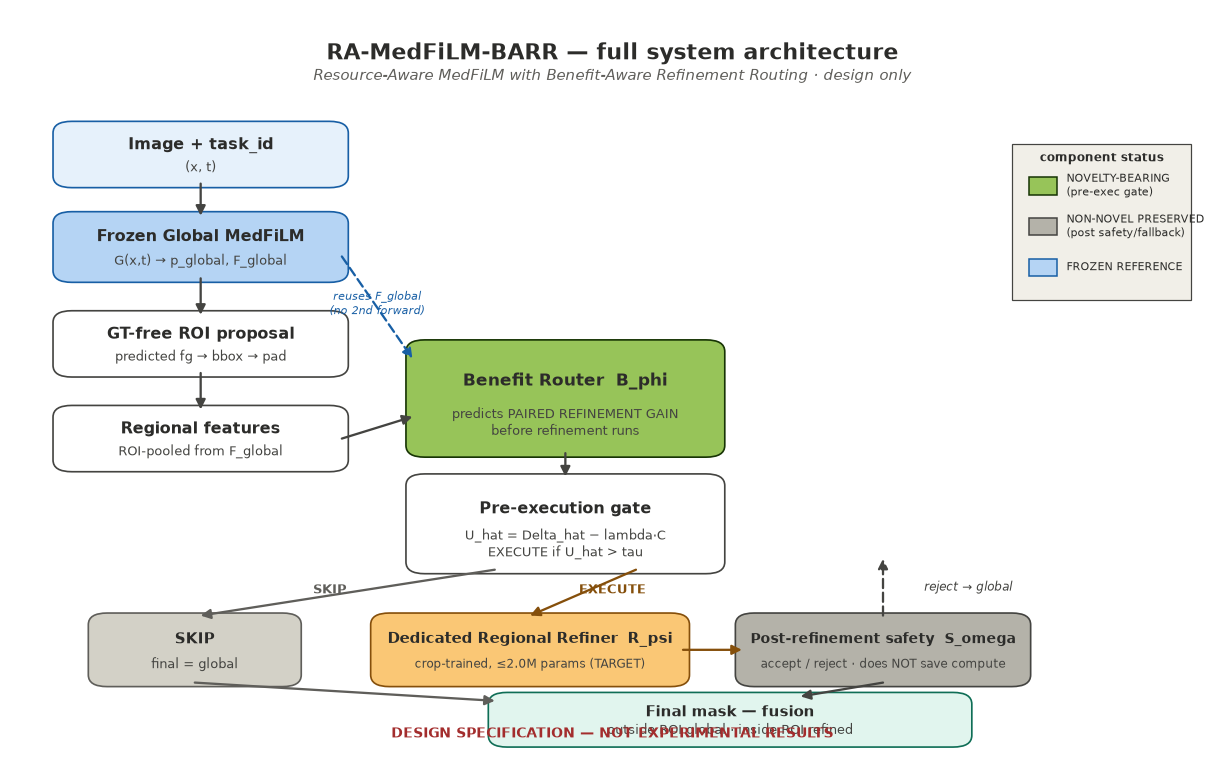

In [4]:
fig("p24_full_system_architecture.png",
    "Figure 1 — Full system architecture (DESIGN SPECIFICATION — NOT EXPERIMENTAL RESULTS)")

In [5]:
ms = pd.read_csv(TAB / "phase24_module_spec.csv")
print(f"module spec: {len(ms)} rows x {len(ms.columns)} cols")
display(sty(ms, "p24-modules"))

module spec: 7 rows x 9 cols


,module_id,name,symbol,role,novelty_bearing,parameter_target,gt_free_at_inference,executed_in_phase24,notes
0,GLOBAL,Frozen Global MedFiLM reference,G,fallback output + reusable features,no,"3523001 (frozen, measured in Phase 21)",yes,no,Phase-21 SHA bound; MUST NOT be modified in initial Phase-25 experiments
1,ROI,GT-free region proposal,P_roi,propose refinement region,no,0 (rule-based),yes,no,foreground bbox + fixed context expansion; constants from TRAIN only
2,R,Dedicated regional refiner,R_psi,produce optional refinement,no,"0.5M-1.5M recommended, <=2.0M hard ceiling (TARGET, unmeasured)",yes,no,crop-trained lightweight residual U-Net; NOT the frozen global model on crops
3,B,Benefit router (paired-gain predictor),B_phi,predict paired refinement gain BEFORE refinement,YES (in integration),"<=250k params; <=2% global MACs (preferred 1%) (TARGET, unmeasured)",yes,no,small MLP / shallow feature fusion; no transformer/encoder
4,GATE,Pre-execution resource-aware gate,U_hat > tau,EXECUTE/SKIP decision,YES (with B),0,yes,no,must not require running R_psi (C4)
5,S,Post-refinement safety selector,S_omega,preserve quality after refinement,no (closest to JFS),0,yes,no,does NOT save compute; CONTROLLED_CORE_EXTENSION
6,FUSE,Fusion rule,F,compose final mask,no,0,yes,no,"outside ROI global, inside ROI refined; no learned fusion in primary"


## 7. Global reference — the frozen anchor

The Phase-21 Global MedFiLM is bound by SHA and **must not be modified** during the initial
controlled Phase-25 experiments. It supplies the fallback output and — critically — the
reusable features `F_global`.

**Feature-reuse requirement.** The router MUST reuse `F_global`. A *second* full Global MedFiLM
forward purely to make the routing decision is **FORBIDDEN**: it would destroy the
compute-saving claim (Phase-23 constraint C4).

In [6]:
arch = _j(AUD / "phase24_architecture_spec.json")
g = arch.get("global_reference", {})
print("role               :", g.get("role"))
print("signature          :", g.get("signature"))
print("architecture       :", g.get("architecture"))
print("parameters         :", f"{g.get('parameters'):,}")
print("sha256             :", str(g.get("sha256"))[:32], "...")
print("modification policy:", g.get("modification_policy"))
print()
print("feature reuse rule :", g.get("feature_reuse_requirement"))
print()
prev = gate.get("bindings", {})
print("checkpoint SHA matches entry gate:",
      g.get("sha256") == prev.get("phase21_best_pt_sha256"))

role               : frozen anchor; produces the fallback output and the reusable features
signature          : G(x, t) -> (p_global, F_global)
architecture       : global_medfilm_shared_residual_unet_film5_no_se_no_deep_supervision_v1
parameters         : 3,523,001
sha256             : 286689fdd5c63ad75a383151d267af8b ...
modification policy: MUST NOT be modified during the initial controlled Phase-25 experiments. Any fine-tuning of the global model is a separate, later, explicitly authorised change.

feature reuse rule : The router MUST reuse F_global. A SECOND full Global MedFiLM forward purely to make the routing decision is FORBIDDEN: it would destroy the compute-saving claim (C4).

checkpoint SHA matches entry gate: True


## 8. GT-free region proposal `P_roi`

Frozen rule: predicted foreground → tight bounding box → fixed context expansion → clip →
square pad → resize to the refiner resolution.

- Constants derived from **TRAIN only**; tuning on VAL **forbidden**; GT rescue **forbidden**.
- `empty_global_prediction` primary behaviour = **`A_SKIP_REFINEMENT`**: the minimal, GT-free,
  zero-extra-cost rule. If the global model predicts no foreground there is no region to refine
  and the fallback preserves the global output.
- A deterministic cheap uncertainty rescue is retained **only** as a pre-registered controlled
  ablation, with constants from TRAIN only and frozen before Phase 25.

In [7]:
rp = arch.get("region_proposal", {})
print("gt_free            :", rp.get("gt_free"))
print("frozen rule        :", rp.get("frozen_rule"))
print("constants source   :", rp.get("constants_source"))
print("val tuning forbidden:", rp.get("tuning_on_val_forbidden"))
print("empty-pred primary :", rp.get("empty_global_prediction_primary_behavior"))
print("gt rescue forbidden:", rp.get("gt_rescue_forbidden"))

gt_free            : True
frozen rule        : p_global predicted foreground -> tight bounding box -> fixed context expansion -> clip to image -> square pad -> resize to regional-refiner resolution
constants source   : TRAIN only (context expansion factor, refiner resolution)
val tuning forbidden: True
empty-pred primary : A_SKIP_REFINEMENT
gt rescue forbidden: True


## 9. Dedicated regional refiner `R_psi`

**Must not be** the frozen Global MedFiLM checkpoint reused on resampled crops — Phase 22 showed
that reuse was **harmful in aggregate** (−0.0425 macro, negative in every domain).

| Property | Value |
|---|---|
| Class | dedicated crop-trained lightweight residual U-Net / encoder–decoder |
| Input contract | `[R, G, B, p_global_crop]`; task/domain conditioning permitted |
| Forbidden inputs | GT mask, GT geometry, GT size category, any GT-derived score |
| Parameter envelope (DESIGN TARGET, **unmeasured**) | 0.5M–1.5M recommended; **hard ceiling 2.0M** |
| Output role | a **candidate**, never a replacement, until the final selection |
| Novelty claimed | **False** |

In [8]:
rr = arch.get("regional_refiner", {})
print("must_not_be        :", rr.get("must_not_be"))
print("class              :", rr.get("class"))
print("input contract     :", rr.get("input_contract", {}).get("conceptual"))
print("forbidden inputs   :", rr.get("input_contract", {}).get("forbidden_inputs"))
env = rr.get("target_parameter_envelope", {})
print("param envelope     :", f"{env.get('recommended_min'):,} - {env.get('recommended_max'):,}"
      f"  (hard ceiling {env.get('hard_ceiling'):,})")
print("measured?          :", env.get("measured"), " <- DESIGN TARGET ONLY")
print("novelty claimed    :", rr.get("novelty_claimed"))

must_not_be        : the frozen Global MedFiLM checkpoint reused on resampled crops. Phase 22 showed that reuse was HARMFUL in aggregate.
class              : dedicated crop-trained lightweight residual U-Net / encoder-decoder
input contract     : [R, G, B, p_global]
forbidden inputs   : ['GT mask', 'GT geometry', 'GT size category', 'any GT-derived score']
param envelope     : 500,000 - 1,500,000  (hard ceiling 2,000,000)
measured?          : False  <- DESIGN TARGET ONLY
novelty claimed    : False


## 10. Benefit router `B_phi` — the novelty-bearing component

Its job is to estimate the expected **paired refinement gain** *before* `R_psi` executes. It is
**not** an uncertainty predictor.

- `pre_refinement = True`, `gt_free = True`.
- Output: primary `Delta_hat_Dice`; optional auxiliary `p_harm`.
- Architecture family: small MLP / shallow feature-fusion network. Forbidden: transformer router,
  foundation model, a second image encoder.
- Envelopes (**DESIGN TARGETS, unmeasured**): ≤ **250,000** params; ≤ **2%** of one global
  forward's analytical MACs, preferred **1%**.

In [9]:
br = arch.get("benefit_router", {})
print("symbol / pre_refine:", br.get("symbol"), "/", br.get("pre_refinement"))
print("gt_free            :", br.get("gt_free"))
print("job                :", br.get("job"))
print("output (primary)   :", br.get("output", {}).get("primary"))
print("architecture family:", br.get("architecture_family"))
print("forbidden arch     :", br.get("forbidden_architecture"))
pe = br.get("target_parameter_envelope", {})
ce = br.get("compute_envelope", {})
print("max params         :", f"{pe.get('max_parameters'):,}", " measured?", pe.get("measured"))
print("max MACs fraction  :", ce.get("max_analytical_macs_fraction_of_one_global_forward"),
      " preferred:", ce.get("preferred_fraction"), " measured?", ce.get("measured"))

symbol / pre_refine: B_phi / True
gt_free            : True
job                : estimate the expected PAIRED REFINEMENT GAIN before R_psi executes. It is NOT an uncertainty predictor.
output (primary)   : Delta_hat_Dice (predicted paired Dice gain)
architecture family: small MLP / shallow feature-fusion network
forbidden arch     : ['transformer router', 'foundation model', 'second image encoder']
max params         : 250,000  measured? False
max MACs fraction  : 0.02  preferred: 0.01  measured? False


## 11. Router input contract

Every router input must satisfy **all three** fail-closed properties:
`uses_GT = false` **AND** `available_pre_refinement = true` **AND** `inference_available = true`.

A GT-derived feature would make the router unavailable at deployment; a post-refinement feature
would break the pre-execution gate (Phase-23 constraints C1 and C4).

In [10]:
ric = pd.read_csv(TAB / "phase24_router_input_contract.csv")

def _b(series):
    """Robust bool dtype: accepts real bools and the literal strings true/false/yes/no.

    Always returns a genuine bool dtype, because ~ on an object-dtype Series of Python
    bools performs an INTEGER bitwise NOT (~True == -2, truthy) instead of a logical not.
    """
    if series.dtype == bool:
        return series
    return (series.astype(str).str.lower()
            .map({"true": True, "false": False, "yes": True, "no": False})
            .fillna(False).astype(bool))

ric["_allowed"] = _b(ric["allowed"])
ric["_uses_gt"] = _b(ric["uses_GT"])
ric["_pre"] = _b(ric["available_pre_refinement"])
ric["_inf"] = _b(ric["inference_available"])

allowed = ric[ric["_allowed"]]
forbidden = ric[~ric["_allowed"]]
print(f"router input contract: {len(ric)} rows ({len(allowed)} allowed / {len(forbidden)} forbidden)")

# FAIL-CLOSED: every allowed row must be GT-free, pre-refinement and inference-available
bad = allowed[allowed["_uses_gt"] | (~allowed["_pre"]) | (~allowed["_inf"])]
print("allowed rows violating the GT-free contract:", len(bad))
assert len(bad) == 0, "FAIL-CLOSED: an allowed router input is not GT-free/pre-refinement"
print("all allowed inputs are GT-free, pre-refinement and inference-available: PASS")
display(sty(allowed[["feature", "source", "primary_or_optional"]], "p24-ric-allowed"))
display(sty(forbidden[["feature", "reason"]], "p24-ric-forbidden"))

router input contract: 31 rows (15 allowed / 16 forbidden)
allowed rows violating the GT-free contract: 0
all allowed inputs are GT-free, pre-refinement and inference-available: PASS


,feature,source,primary_or_optional
0,global_encoder_pooled_features,F_global (global forward),primary
1,global_decoder_pooled_features,F_global (global forward),primary
2,roi_pooled_global_features,F_global pooled over the proposed ROI,primary
3,probability_entropy_summaries,p_global,primary
4,probability_margin_summaries,p_global,primary
5,probability_percentiles,p_global,optional
6,predicted_foreground_fraction,p_global (thresholded),primary
7,predicted_component_count,p_global (connected components),optional
8,predicted_largest_component_ratio,p_global,optional
9,predicted_bbox_width_height,p_global (ROI bbox),primary


,feature,reason
15,GT_mask,direct label leakage
16,GT_foreground_fraction,direct label leakage
17,GT_size_label,direct label leakage
18,Dice,the target itself; unavailable at deployment
19,IoU,GT-derived
20,recall,GT-derived
21,precision,GT-derived
22,specificity,GT-derived
23,MCC,GT-derived
24,GT_derived_ECE,GT-derived


## 12. Paired refinement gain contract

$$\Delta\mathrm{Dice}_i = \mathrm{Dice}(R_i, y_i) - \mathrm{Dice}(G_i, y_i)$$

This is a **supervised paired contrast**. During development both arms are fully observed — the
system may simply run the refinement. There is **no missing arm and therefore no identification
problem**, and the refinement is deterministic given `(x, frozen model, frozen ROI rule)`. It
**must not** be described as a causal / counterfactual / individual treatment effect.

The CATE analogy may be stated **at most once**, with the clarification that the estimand is a
deterministic paired contrast.

In [11]:
pg = _j(AUD / "phase24_paired_refinement_gain_contract.json")
print("primary term       :", pg.get("primary_term"))
print("definition         :", pg.get("definition"))
print("nature             :", pg.get("nature"))
print("must_not_describe  :", pg.get("must_not_be_described_as"))
print("why not causal     :", pg.get("why_not_causal"))
print()
print("uses_GT_for_labels :", pg.get("uses_GT_for_labels"))
print("uses_GT_for_inputs :", pg.get("uses_GT_for_inputs"), " <- labels only")
print("used as router input:", pg.get("computation_used_as_router_input"))
print("training population:", pg.get("training_population"))

primary term       : PAIRED REFINEMENT GAIN
definition         : DeltaDice_i = Dice(R_i, y_i) - Dice(G_i, y_i)
nature             : supervised paired contrast (both arms fully observed during TRAIN development)
must_not_describe  : ['causal treatment effect', 'counterfactual effect', 'individual treatment effect']
why not causal     : Both potential outcomes are fully observed for every development image because the system may simply run the refinement during development. There is no missing arm and therefore no identification problem. The refinement is also deterministic given (x, frozen model, frozen ROI rule). See Phase-23 outcome PREFER_PAIRED_REFINEMENT_GAIN.

uses_GT_for_labels : True
uses_GT_for_inputs : False  <- labels only
used as router input: False
training population: original TRAIN only (never Phase-22 VAL, never TEST)


## 13. TRAIN-only data protocol

**Critical leakage constraint:** benefit-router training labels may **never** be generated from the
existing Phase-22 VAL population. Only original TRAIN may be used.

| Population | n | Role |
|---|---|---|
| Original TRAIN | **5832** | source of the two router splits |
| `ROUTER_DEVELOPMENT` (85%) | **≈4957** | cross-fitted gain labels + router fitting + threshold calibration |
| `ROUTER_HOLDOUT` (15%) | **≈875** | clean out-of-sample routing evaluation |
| VAL (existing) | **808** | `SECONDARY / CONTINUITY DEVELOPMENT BENCHMARK` |
| TEST | 1683 | **CLOSED** |

In [12]:
dp = _j(AUD / "phase24_benefit_data_protocol.json")
tr = dp.get("original_train", {})
sp = dp.get("split", {})
print("manifest           :", tr.get("manifest"))
print("n_cases            :", tr.get("n_cases"))
print("domains            :", tr.get("domains"))
print("grouping key       :", tr.get("grouping_key"))
print()
for k in ("ROUTER_HOLDOUT", "ROUTER_DEVELOPMENT"):
    s = sp.get(k, {})
    print(f"{k:20s} {s.get('fraction')}  ~{s.get('approx_cases')}  {s.get('status')}")
print("domain_stratified  :", sp.get("domain_stratified"))
print("group_safe         :", sp.get("group_safe"))
print("overlap            :", sp.get("overlap"))
print("uses_phase22_val   :", sp.get("uses_phase22_val"))
print("uses_test          :", sp.get("uses_test"))

manifest           : manifests/phase4_v3/train.csv
n_cases            : 5832
domains            : {'KUB': 1978, 'KVASIR': 696, 'ISIC': 2556, 'BUSI': 602}
grouping key       : patient_id

ROUTER_HOLDOUT       0.15  ~875  designated_never_inspected_for_outcomes
ROUTER_DEVELOPMENT   0.85  ~4957  used for cross-fitted label generation and router fitting in Phase 25
domain_stratified  : True
group_safe         : True
overlap            : 0
uses_phase22_val   : False
uses_test          : False


**Figure 2 — TRAIN-only router development protocol (DESIGN SPECIFICATION — NOT EXPERIMENTAL RESULTS)**

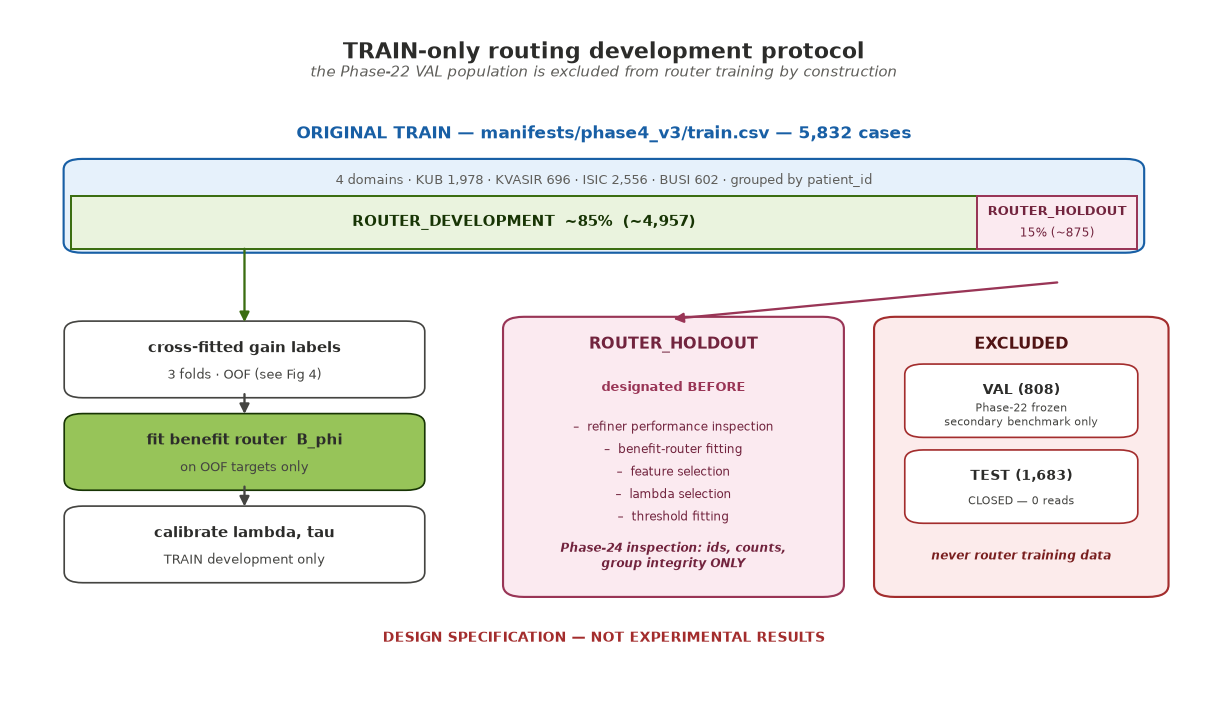

In [13]:
fig("p24_train_router_holdout_flow.png",
    "Figure 2 — TRAIN-only router development protocol (DESIGN SPECIFICATION — NOT EXPERIMENTAL RESULTS)")

## 14. `ROUTER_HOLDOUT` discipline

The holdout is designated **before** any refiner-performance inspection, benefit-router fitting,
feature selection, lambda selection or threshold fitting. In Phase 24 only **structural** facts
were inspected.

In [14]:
rh = arch.get("router_holdout_contract", {})
print("designated_before  :")
for x in rh.get("designated_before", []):
    print("   -", x)
print()
print("inspected_in_phase24 (allowed):", rh.get("inspected_in_phase24"))
print("must_not_inspect_in_phase24   :")
for x in rh.get("must_not_inspect_in_phase24", []):
    print("   -", x)
print()
print("outcomes_read_in_phase24:", rh.get("outcomes_read_in_phase24"))
assert rh.get("outcomes_read_in_phase24") == 0

designated_before  :
   - refiner performance inspection
   - benefit-router fitting
   - feature selection based on performance
   - lambda selection
   - threshold fitting

inspected_in_phase24 (allowed): ['sample_ids', 'domain_counts', 'group_integrity', 'manifest_sha', 'split_seed']
must_not_inspect_in_phase24   :
   - DeltaDice distribution
   - Dice
   - router AUC
   - benefit distribution
   - routing policy performance

outcomes_read_in_phase24: 0


## 15. VAL reclassification and TEST lock

The existing frozen Phase-22 808-case VAL is reclassified as a
**`SECONDARY / CONTINUITY DEVELOPMENT BENCHMARK`**. It is **not** router training data and
**not** an untouched routing holdout. This reclassification is stated in every protocol artifact.

In [15]:
vr = arch.get("VAL_role", {})
print("population         :", vr.get("population"))
print("role               :", vr.get("role"))
print("is_router_train    :", vr.get("is_router_training_data"))
print("is_untouched_holdout:", vr.get("is_untouched_routing_holdout"))
print("explicit everywhere:", vr.get("explicit_in_all_protocol_artifacts"))
print()
tl = arch.get("TEST_lock", {})
print("TEST lock          :", tl)
assert all(v == 0 for k, v in tl.items() if k != "status")
print()
drc = pd.read_csv(TAB / "phase24_data_role_contract.csv")
display(sty(drc, "p24-datarole"))

population         : existing frozen Phase-22 808-case VAL
role               : SECONDARY / CONTINUITY DEVELOPMENT BENCHMARK
is_router_train    : False
is_untouched_holdout: False
explicit everywhere: True

TEST lock          : {'image_reads': 0, 'mask_reads': 0, 'inference': 0, 'visualization': 0, 'status': 'CLOSED'}



,population,source,n_cases,role,may_train_router,may_select_lambda_or_threshold,is_untouched_holdout,inspected_in_phase24
0,TRAIN (original),manifests/phase4_v3/train.csv,5832,source of ROUTER_HOLDOUT + ROUTER_DEVELOPMENT,yes (via ROUTER_DEVELOPMENT only),yes (ROUTER_DEVELOPMENT only),partially (ROUTER_HOLDOUT),counts only
1,ROUTER_DEVELOPMENT,85% of original TRAIN,~4957,cross-fitted gain labels + router fitting + threshold calibration,yes,yes,no,counts only
2,ROUTER_HOLDOUT,15% of original TRAIN,~875,clean out-of-sample routing evaluation,NO,NO,YES (outcomes never inspected),ids/counts/groups only
3,VAL (existing),manifests/phase4_v3/val.csv (Phase-22 frozen),808,SECONDARY / CONTINUITY DEVELOPMENT BENCHMARK,NO,NO,NO,not used
4,TEST,manifests/phase4_v3/test.csv,1683,CLOSED,NO,NO,YES,0 reads


## 16. Out-of-fold 3-fold cross-fitting

Within `ROUTER_DEVELOPMENT`: for fold *k*, train `R_psi` on folds ≠ *k*, infer `R_psi` on fold *k*,
and compute `DeltaDice_i` for fold-*k* samples. The concatenation yields **out-of-fold** gain labels.

Purpose: prevent refiner-overfit gain labels from entering the router target. The refiner must be
**cross-fitted**, never fit and evaluated on the same samples.

**Figure 3 — Out-of-fold paired-gain label generation (DESIGN SPECIFICATION — NOT EXPERIMENTAL RESULTS)**

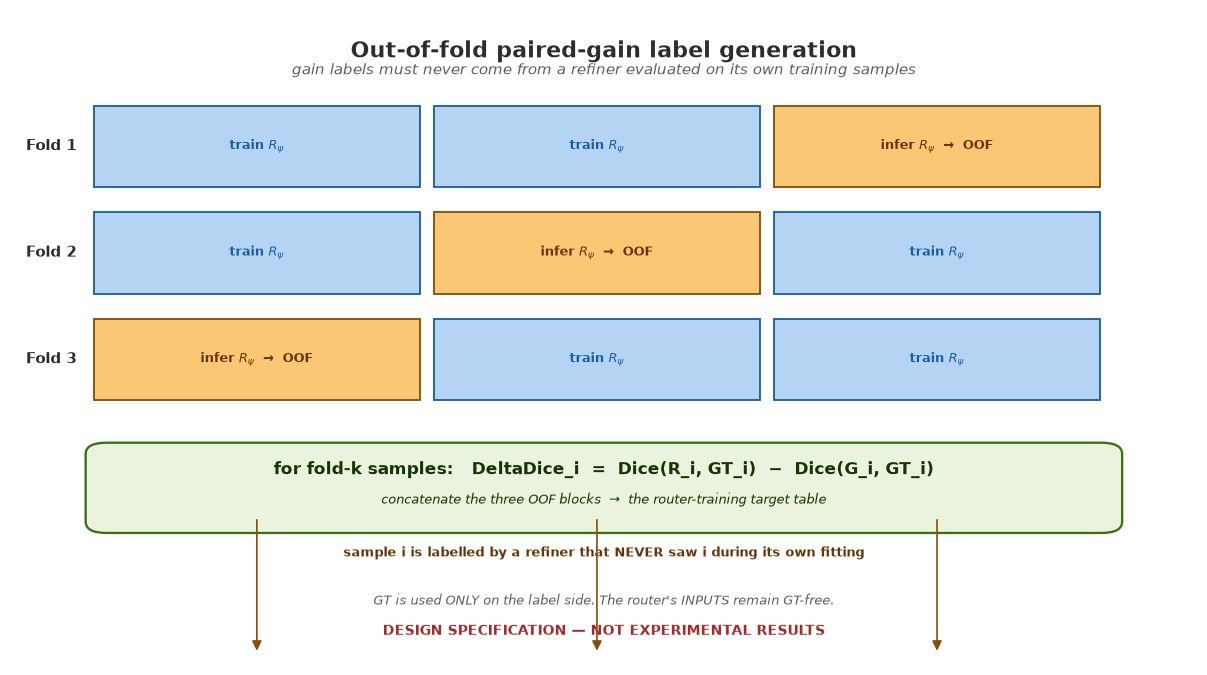

In [16]:
fig("p24_crossfit_gain_label_generation.png",
    "Figure 3 — Out-of-fold paired-gain label generation (DESIGN SPECIFICATION — NOT EXPERIMENTAL RESULTS)")

In [17]:
cf = arch.get("crossfit_contract", {})
print("folds              :", cf.get("folds"))
print("within             :", cf.get("within"))
print("procedure          :", cf.get("procedure"))
print("output             :", cf.get("output"))
print("executed_in_phase24:", cf.get("executed_in_phase24"))
assert cf.get("executed_in_phase24") is False

folds              : 3
within             : ROUTER_DEVELOPMENT subset of original TRAIN
procedure          : For fold k: train R_psi on folds != k, infer R_psi on fold k, compute DeltaDice_i = Dice(R_i, GT) - Dice(G_i, GT) for fold-k samples.
output             : concatenated out-of-fold (OOF) paired-gain labels
executed_in_phase24: False


## 17. Pre-execution resource utility

$$\hat{U}_i = \hat{\Delta}_i - \lambda C_i \quad\Rightarrow\quad \hat{U}_i > \tau \;\Rightarrow\; \text{EXECUTE, else SKIP}$$

A **single universal lambda is forbidden**. A small set of lambda values is pre-registered with a
fixed-budget sweep: **0% / 10% / 25% / 50% / 100%** (0% = global-only, 100% = always-refine).

**Cost terminology.** Cost is **normalized analytical incremental MACs**. Analytical MACs is **not**
latency and must never be described as CPU/mobile latency; device measurement belongs to Phase 34.
The cost term is required by Phase-23 constraint **C6**.

In [18]:
ru = _j(AUD / "phase24_resource_utility_contract.json")
print("utility            :", ru.get("utility"))
print("decision rule      :", ru.get("decision_rule"))
print("single lambda forbidden:", ru.get("single_universal_lambda_forbidden"))
print("fixed budget points:", ru.get("fixed_budget_evaluation", {}).get("points"))
print("cost proxy         :", ru.get("cost_proxy", {}).get("primary_for_phase25"))
print("kept separate      :", ru.get("cost_proxy", {}).get("terminology_kept_separate"))
print("analytical != latency:", ru.get("cost_proxy", {}).get("analytical_macs_is_not_latency"))
print("device measurement phase:", ru.get("cost_proxy", {}).get("device_measurement_phase"))
print("required by        :", ru.get("cost_term_required_by"))
print("measured in phase24:", ru.get("measured_in_phase24"))

utility            : U_hat_i = Delta_hat_i - lambda * C_i
decision rule      : {'if': 'U_hat_i > tau', 'then': 'EXECUTE', 'else': 'SKIP'}
single lambda forbidden: True
fixed budget points: ['0%', '10%', '25%', '50%', '100%']
cost proxy         : normalized analytical incremental MACs
kept separate      : ['ANALYTICAL MACs', 'MEASURED latency', 'MEASURED memory', 'MEASURED energy']
analytical != latency: True
device measurement phase: 34
required by        : Phase-23 constraint C6
measured in phase24: False


**Figure 4 — Pre-registered fixed-budget evaluation grid (DESIGN SPECIFICATION — NOT EXPERIMENTAL RESULTS)**

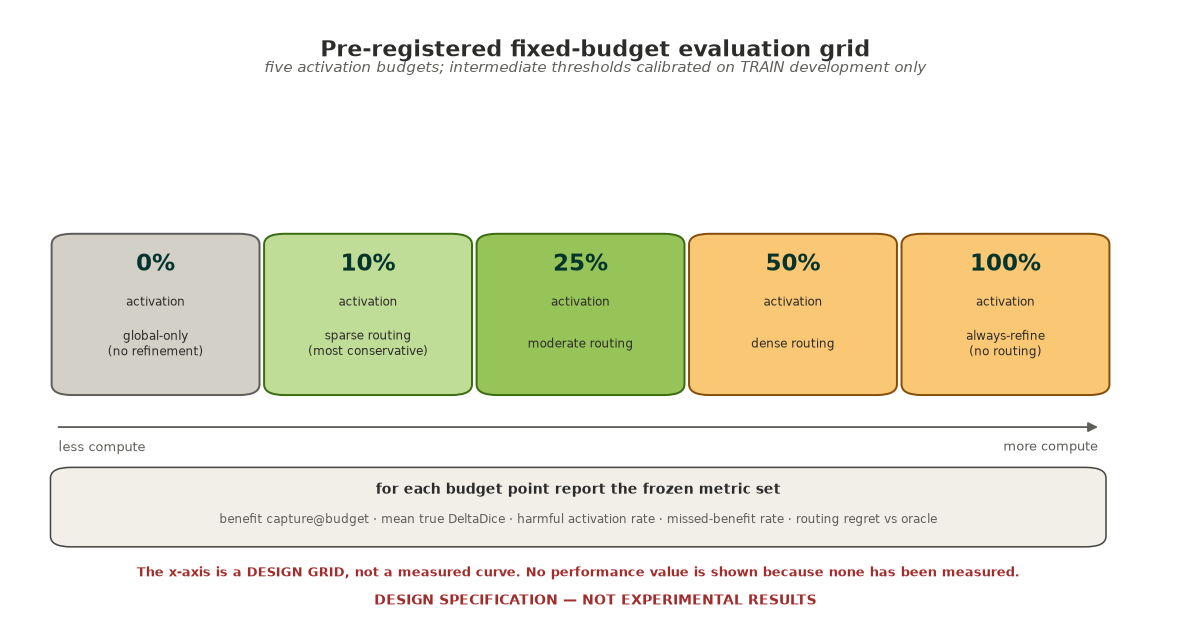

In [19]:
fig("p24_resource_budget_evaluation.png",
    "Figure 4 — Pre-registered fixed-budget evaluation grid (DESIGN SPECIFICATION — NOT EXPERIMENTAL RESULTS)")

## 18. The pivotal separation: pre-execution gate vs post-refinement safety

This separation is the **load-bearing structural claim** of the narrowed specification.

| | Pre-execution gate | Post-refinement safety `S_omega` |
|---|---|---|
| Rule | `if U_hat > tau then EXECUTE else SKIP` | accept or reject the refinement output |
| When | **before** `R_psi` executes | **after** `R_psi` has executed |
| Saves compute? | **YES** | **NO** |
| Novelty | part of the residual | `CONTROLLED_CORE_EXTENSION`, closest to JFS |
| Mandated ablation | — | A7 (no post-safety) vs A8 (with post-safety) |

`S_omega` must **NEVER** be presented as the compute-saving mechanism, because JFS already occupies
the post-hoc decision. Post-hoc selection ≠ pre-execution routing.

**Figure 5 — Pre-execution gate vs post-refinement safety (DESIGN SPECIFICATION — NOT EXPERIMENTAL RESULTS)**

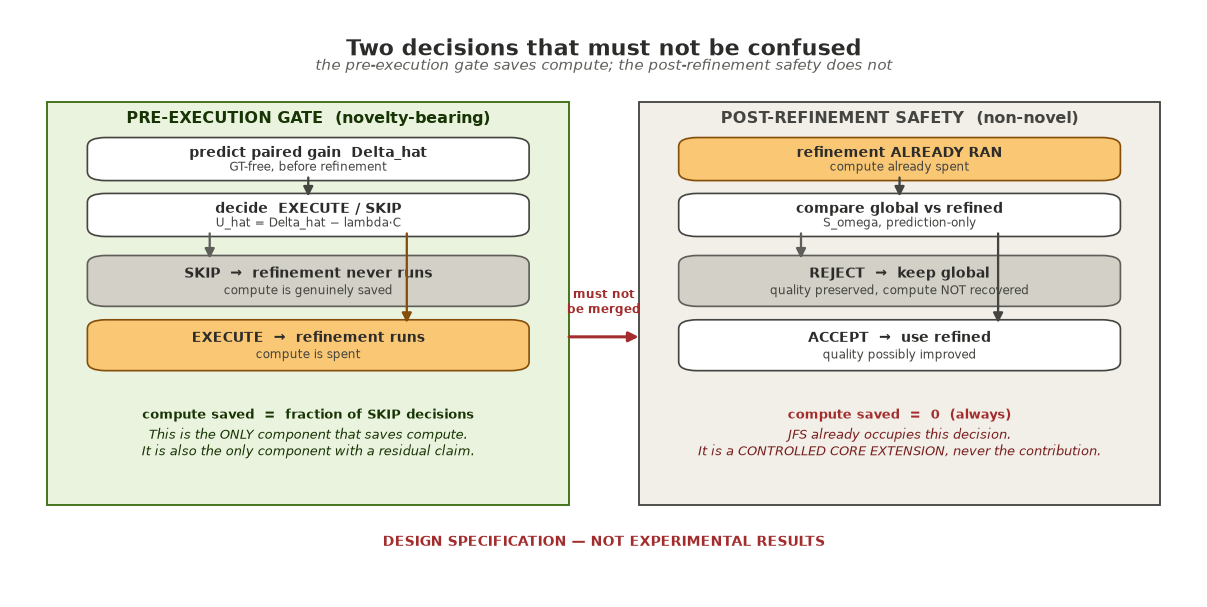

In [20]:
fig("p24_pre_gate_vs_post_safety.png",
    "Figure 5 — Pre-execution gate vs post-refinement safety (DESIGN SPECIFICATION — NOT EXPERIMENTAL RESULTS)")

In [21]:
pg2 = arch.get("pre_execution_gate", {})
ps = arch.get("post_safety", {})
print("pre-execution gate :", pg2.get("rule"), "| evaluates", pg2.get("evaluated_before"))
print("fixed budget points:", pg2.get("fixed_budget_points"))
print()
print("post-safety symbol :", ps.get("symbol"))
print("post-safety role   :", ps.get("role"))
print("saves compute      :", ps.get("saves_compute"), " <- NOT the compute saver")
print("classification     :", ps.get("classification"))
print("mandatory ablation :", ps.get("mandatory_ablation"))
print("novelty claimed    :", ps.get("novelty_claimed"))

pre-execution gate : if U_hat_i > tau then EXECUTE else SKIP | evaluates R_psi execution
fixed budget points: ['0%', '10%', '25%', '50%', '100%']

post-safety symbol : S_omega
post-safety role   : quality preservation AFTER refinement
saves compute      : False  <- NOT the compute saver
classification     : CONTROLLED_CORE_EXTENSION
mandatory ablation : A7 (router, no post-safety) vs A8 (router + post-safety)
novelty claimed    : False


## 19. Preservation fallback and non-inferiority

The global output must remain **available** until the final selection. **No destructive replacement**
may occur before the final decision.

| Outcome | Final output |
|---|---|
| `SKIP` | global |
| `EXECUTE_THEN_REJECT` | global |
| `EXECUTE_THEN_ACCEPT` | regional-fused |

**Non-inferiority test (frozen before Phase 25):** `Delta = Dice(final routed) − Dice(global)`;
margin **0.005**; the claim is permitted **only if** the lower confidence bound of `Delta > −0.005`.
Per-domain reporting is **mandatory** — the macro average may not hide domain-specific harm.

In [22]:
pc = _j(AUD / "phase24_preservation_contract.json")
print("principle          :", pc.get("principle"))
for k, v in pc.get("outcomes", {}).items():
    print(f"  {k:22s} -> {v}")
print("destructive replacement before decision:", pc.get("destructive_replacement_before_final_decision"))
print()
ni = pc.get("non_inferiority", {})
print("metric             :", ni.get("metric"))
print("margin             :", ni.get("margin"))
print("claim only if      :", ni.get("claim_only_if"))
print("per-domain report  :", ni.get("per_domain_reporting"))
print("macro may not hide :", ni.get("macro_may_not_hide_domain_harm"))

principle          : The global output must remain AVAILABLE until the final selection. No destructive replacement may occur before the final decision.
  SKIP                   -> final = global
  EXECUTE_THEN_REJECT    -> final = global
  EXECUTE_THEN_ACCEPT    -> final = regional-fused
destructive replacement before decision: False

metric             : Delta = Dice(final routed system) - Dice(global reference)
margin             : 0.005
claim only if      : lower confidence bound of Delta > -0.005
per-domain report  : mandatory
macro may not hide : True


## 20. Fusion and task conditioning

- Fusion primary rule: **outside ROI retain `p_global`; inside ROI replace with `p_refined`.**
  **No learned fusion in the primary design** — it would confound the benefit-routing hypothesis.
  Learned fusion is a future controlled ablation only.
- Task conditioning: **ONE shared router**, task/domain conditioning allowed. Separate per-domain
  routers are **forbidden** in the primary design (this preserves the shared multi-domain
  contribution); they are later controlled ablations only.

In [23]:
fr = arch.get("fusion_rule", {})
tc = arch.get("task_conditioning", {})
print("fusion primary     :", fr.get("primary"))
print("learned fusion pri.:", fr.get("learned_fusion_in_primary"))
print("reason             :", fr.get("reason"))
print("future             :", fr.get("learned_fusion"))
print()
print("task conditioning  :", tc.get("primary_design"))
print("per-domain routers :", tc.get("separate_per_domain_routers"))
print("reason             :", tc.get("reason"))

fusion primary     : outside ROI retain p_global; inside ROI replace with p_refined
learned fusion pri.: False
reason             : avoid confounding the benefit-routing hypothesis
future             : future controlled ablation only

task conditioning  : ONE shared router with task/domain conditioning allowed
per-domain routers : forbidden in the primary design
reason             : preserve the shared multi-domain system contribution


## 21. Hypotheses — PRE-REGISTERED, NOT RESULTS

**H1 is load-bearing.** If H1 fails, the narrowed contribution has no empirical support.

In [24]:
hy = arch.get("hypotheses", {})
print("status             :", hy.get("status"))
print("load-bearing       :", hy.get("load_bearing"))
print()
for k in ("H1", "H2", "H3", "H4", "H5", "H6"):
    print(f"{k}: {hy.get(k)}")
    print()

status             : HYPOTHESES_NOT_RESULTS
load-bearing       : H1

H1: A learned pre-execution GT-free predictor of paired refinement gain can allocate optional regional refinement more effectively than simple GT-free uncertainty/geometry proxies at equal refinement-activation budgets.

H2: benefit-aware routing captures more positive gain per unit compute than random/entropy/margin/ROI-size routing.

H3: post-refinement fallback reduces harmful replacement relative to always accepting an executed refinement.

H4: a dedicated crop-trained regional refiner yields a more useful action distribution than the Phase-22 diagnostic reuse of the full-field model.

H5: benefit-aware routing produces a measurable accuracy-compute frontier.

H6: learned paired refinement gain contains information beyond ordinary global uncertainty.



## 22. Pre-registered comparators (11 rows, **no ranking**)

`C7 LEARNED_PAIRED_GAIN_ROUTING` is the load-bearing comparator. `C10 ORACLE_BENEFIT_ROUTING`
is an upper bound only — it uses GT, is **not deployable**, and is never a result.
`C11 JFS_LIKE_POST_HOC_SELECTOR` is optional; if included it must record **full** refinement compute,
because the expensive operation already occurred.

In [25]:
cp = pd.read_csv(TAB / "phase24_comparator_plan.csv")
print(f"comparators: {len(cp)} rows x {len(cp.columns)} cols")
display(sty(cp, "p24-comparators"))

comparators: 11 rows x 7 cols


,comparator_id,name,compute_order,uses_GT,deployable,role,notes
0,C1,GLOBAL_ONLY,1x (global forward only),False,yes,lower compute anchor,defines the preservation reference
1,C2,ALWAYS_REFINE,1x + refinement always,False,yes,upper compute anchor,"maximum action, no routing"
2,C3,RANDOM_ROUTING,budget-matched,False,yes,null routing baseline,"seeded, budget-matched"
3,C4,ENTROPY_ROUTING,budget-matched,False,yes,simple GT-free uncertainty proxy,occupies the 'uncertainty' objection
4,C5,MARGIN_ROUTING,budget-matched,False,yes,simple GT-free margin proxy,second simple proxy
5,C6,PREDICTED_ROI_SIZE_ROUTING,budget-matched,False,yes,simple GT-free geometry proxy,tests the 'just use ROI size' objection
6,C7,LEARNED_PAIRED_GAIN_ROUTING,budget-matched,False,yes,primary proposed method (H1 test),the load-bearing comparator
7,C8,LEARNED_GAIN_PLUS_RESOURCE_COST,budget-matched,False,yes,adds explicit lambda*C term (C6),tests H5
8,C9,LEARNED_GAIN_PLUS_RESOURCE_COST_PLUS_POST_SAFETY,budget-matched,False,yes,adds S_omega preservation,tests H3
9,C10,ORACLE_BENEFIT_ROUTING,budget-matched,True,NO,upper bound only; not deployable,uses true DeltaDice; never a result


## 23. Metrics

Grouped exactly as pre-registered. No metric is added or removed after seeing a result.

In [26]:
m = arch.get("metrics", {})
for k, v in m.items():
    print(f"{k:18s} {', '.join(v)}")

benefit_prediction MAE, RMSE, Spearman, Pearson, ROC-AUC for useful-benefit detection, PR-AUC
routing            precision@budget, benefit capture@budget, mean true DeltaDice among routed cases, harmful activation rate, missed-benefit rate, routing regret vs oracle
segmentation       macro-domain Dice, per-domain Dice, IoU, existing standardized boundary metrics
compute            activation fraction, incremental MACs, average total MACs, ratio vs global-only, ratio vs always-refine
preservation       harmful replacement rate, fallback rate, per-domain degradation


## 24. Statistics — paired bootstrap, pre-registered

`n_boot = 2000`, `seed = 42`, domain-stratified for macro-domain metrics. Report the point
estimate, 95% CI, and paired p-value where appropriate. TEST is never used.

In [27]:
st = arch.get("statistics", {})
print("method             :", st.get("method"))
print("n_boot             :", st.get("n_boot"))
print("seed               :", st.get("seed"))
print("domain-stratified  :", st.get("domain_stratified_for"))
print("report             :", st.get("report"))
print("test used          :", st.get("test_used"))

method             : paired bootstrap
n_boot             : 2000
seed               : 42
domain-stratified  : macro-domain metrics
report             : ['point estimate', '95% CI', 'paired p-value where appropriate']
test used          : False


## 25. Success and failure criteria — frozen before Phase 25

**Failures (F1–F5):** `REFINER_FAILURE`, `ROUTER_FAILURE`, `PRESERVATION_FAILURE`,
`RESOURCE_FAILURE`, `DOMAIN_COLLAPSE`.
**Successes (S1–S3):** `H1_SUPPORTED`, `PRESERVATION_SATISFIED`, `FRONTIER_MEASURED`.

In [28]:
sfc = pd.read_csv(TAB / "phase24_success_failure_criteria.csv")
print(f"criteria: {len(sfc)} rows x {len(sfc.columns)} cols")
display(sty(sfc, "p24-criteria"))

criteria: 8 rows x 6 cols


,id,type,name,definition,consequence_if_triggered,frozen_before_phase25
0,F1,failure,REFINER_FAILURE,dedicated refiner does not create enough positive action opportunity,report as a failure; routing has nothing to route,True
1,F2,failure,ROUTER_FAILURE,learned paired gain fails to outperform simple GT-free routing signals out of sample,report H1 as unsupported,True
2,F3,failure,PRESERVATION_FAILURE,routed system materially degrades the global reference,report; non-inferiority claim NOT permitted,True
3,F4,failure,RESOURCE_FAILURE,router/refiner cost removes the useful compute-performance trade-off,report; resource-aware claim NOT permitted,True
4,F5,failure,DOMAIN_COLLAPSE,benefit is concentrated in one domain while another is materially harmed,report per-domain harm; macro average may not hide it,True
5,S1,success,H1_SUPPORTED,learned pre-execution GT-free predictor beats simple proxies at equal budget,enables scoped Level-2 wording for the integrated residual,True
6,S2,success,PRESERVATION_SATISFIED,lower bound of Delta > -0.005 on macro-domain Dice and no domain collapse,allows the phrase 'performance preserving',True
7,S3,success,FRONTIER_MEASURED,a measurable accuracy-compute frontier exists across budget points,supports H5,True


In [29]:
_fr = _b(sfc["frozen_before_phase25"])
assert _fr.all(), "FAIL: a criterion is not frozen"
print("all criteria frozen before Phase 25: PASS")

all criteria frozen before Phase 25: PASS


## 26. Ablation plan — core A0–A8, router R1–R3, refiner F1

None executed in Phase 24; all pre-registered.

In [30]:
ab = pd.read_csv(TAB / "phase24_ablation_plan.csv")
print(f"ablations: {len(ab)} rows x {len(ab.columns)} cols")
_exec = _b(ab["executed_in_phase24"])
assert (~_exec).all(), "FAIL: an ablation claims execution"
print("none executed in Phase 24: PASS")
display(sty(ab, "p24-ablations"))

ablations: 13 rows x 5 cols
none executed in Phase 24: PASS


,ablation_id,name,family,purpose,executed_in_phase24
0,A0,global-only,core,compute floor / preservation reference,no
1,A1,always-refine,core,compute ceiling / no-routing reference,no
2,A2,random routing,core,null routing baseline,no
3,A3,entropy routing,core,simple GT-free uncertainty proxy,no
4,A4,margin routing,core,simple GT-free margin proxy,no
5,A5,predicted-ROI-size routing,core,simple GT-free geometry proxy,no
6,A6,learned paired-gain router,core,H1 test,no
7,A7,A6 + resource cost,core,H5 test,no
8,A8,A7 + post-safety,core,H3 test; isolates S_omega,no
9,R1,router without deep global features,router,does depth matter?,no


## 27. Phase-25 module plan — PRE-REGISTERED, NOT STARTED

Ordering constraint: the router may only be fitted **after** out-of-fold gain labels exist
(25C precedes 25D).

In [31]:
pp = _j(AUD / "phase24_phase25_module_plan.json")
print("status             :", pp.get("status"))
print("phase25_started    :", pp.get("phase25_started"))
print("no_module_started  :", pp.get("no_module_started"))
print()
for mm in pp.get("modules", []):
    dep = ", ".join(mm.get("starts_after") or []) or "-"
    print(f"  {mm.get('id')}  {mm.get('name'):52s} depends on: {dep}")
assert pp.get("no_module_started") is True and pp.get("phase25_started") is False

status             : PRE_REGISTERED_NOT_STARTED
phase25_started    : False
no_module_started  : True

  25A  Dedicated crop-trained regional refiner              depends on: -
  25B  GT-free feature extraction / ROI pipeline            depends on: -
  25C  Out-of-fold paired-gain label generation             depends on: 25A, 25B
  25D  Lightweight paired-gain benefit router               depends on: 25C
  25E  Resource-aware pre-execution gate                    depends on: 25D
  25F  Post-refinement preservation selector + fusion       depends on: 25A
  25G  Integrated controlled development evaluation / freeze depends on: 25E, 25F


## 28. Tiny-structure role — reporting only

Tiny structures are a **stratification of the analysis**, never a tuning target, never a routing
input, and they cannot be used to select lambda or thresholds. This follows the frozen Phase-22
finding that benefit is strongly heterogeneous but not deployably predictable, and the
`kub_size_clean_v3_v1` taxonomy's rule that `<32 px = tiny` is **not** a project definition.

In [32]:
print("tiny-structure role: REPORTING_ONLY")
print("  - not a tuning target")
print("  - not a routing input")
print("  - cannot select lambda or thresholds")
print("  - '<32 px = tiny' is NOT a project definition")
print()
print("KUB taxonomy (frozen):", "kub_size_clean_v3_v1")
print("  Q25/50/75 ratios   :",
      "0.0001497998649691358 / 0.0003401438395182292 / 0.0008279682677469136 (lower-inclusive)")

tiny-structure role: REPORTING_ONLY
  - not a tuning target
  - not a routing input
  - cannot select lambda or thresholds
  - '<32 px = tiny' is NOT a project definition

KUB taxonomy (frozen): kub_size_clean_v3_v1
  Q25/50/75 ratios   : 0.0001497998649691358 / 0.0003401438395182292 / 0.0008279682677469136 (lower-inclusive)


## 29. Feature reuse — bridge / decoder2 / decoder1

The router reads *pooled summaries* of features the global forward has **already produced**. This is
a hard requirement, not an optimisation: re-running the global model to make the routing decision
would erase the compute saving that justifies the whole design.

In [33]:
ric2 = pd.read_csv(TAB / "phase24_router_input_contract.csv")
_ok = _b(ric2["allowed"])
src = ric2[_ok]["source"].value_counts().to_dict()
for k, v in src.items():
    print(f"  {v:2d}  {k}")
print()
print("requirement:", g.get("feature_reuse_requirement"))

   5  p_global
   2  F_global (global forward)
   1  F_global pooled over the proposed ROI
   1  p_global (thresholded)
   1  p_global (connected components)
   1  p_global (ROI bbox)
   1  p_global (ROI area / image area)
   1  ROI rule (deterministic)
   1  task_id t
   1  deployment configuration

requirement: The router MUST reuse F_global. A SECOND full Global MedFiLM forward purely to make the routing decision is FORBIDDEN: it would destroy the compute-saving claim (C4).


## 30. Prior-art differentiation (12 rows, 14 cols, **unranked**)

The closest analogue is JFS, which shares the framing and a paired revert-on-failure comparison but
decides **after** the refinement has run (zero compute saved) with an **untrained** rule. The formal
antecedent is Russell & Wefald's *value of computation*. No row carries a novelty score.

In [34]:
pa = pd.read_csv(TAB / "phase24_prior_art_differentiation.csv")
print(f"prior art: {len(pa)} rows x {len(pa.columns)} cols (no ranking column)")
assert not any(c in pa.columns for c in ("rank", "score", "novelty_score")), "FAIL: ranking present"
display(sty(pa[["citation_key", "year", "pre_execution", "learned_gain",
                 "compute_saved_by_gate"]], "p24-priorart"))

prior art: 12 rows x 14 cols (no ranking column)


,citation_key,year,pre_execution,learned_gain,compute_saved_by_gate
0,moon2024jfs,2024,no (POST-HOC),no (untrained),NO
1,russell1991metareasoning,1991,yes (definitional),no,yes (conceptual)
2,viola2001cascade,2001,yes,no (hand-designed cascade thresholds),yes
3,latotzke2021cascade,2021,yes,no (analytical criteria),yes
4,kunzel2019metalearners,2019,"n/a (estimand, not a system)",yes (supervised T/X/S-learners),no
5,shen2022meddanet,2022,yes,"no (learned band selection, not a quality gain)",yes
6,shen2024meddanetv2,2024,yes,no (learned band selection),yes
7,jiang2024m4oe,2024,no (static per-image routing during the forward pass),"no (expert selection, not a gain)",partial (sparse expert activation)
8,zhang2024adaptivepatching,2024,yes,no (content-based patch allocation),yes
9,mozannar2020defer,2020,yes (defer before deciding),yes (learned deferral policy),yes


## 31. Novelty boundary (visual)

What is claimed versus what is explicitly **not** claimed.

**Figure 6 — Novelty boundary (DESIGN SPECIFICATION — NOT EXPERIMENTAL RESULTS)**

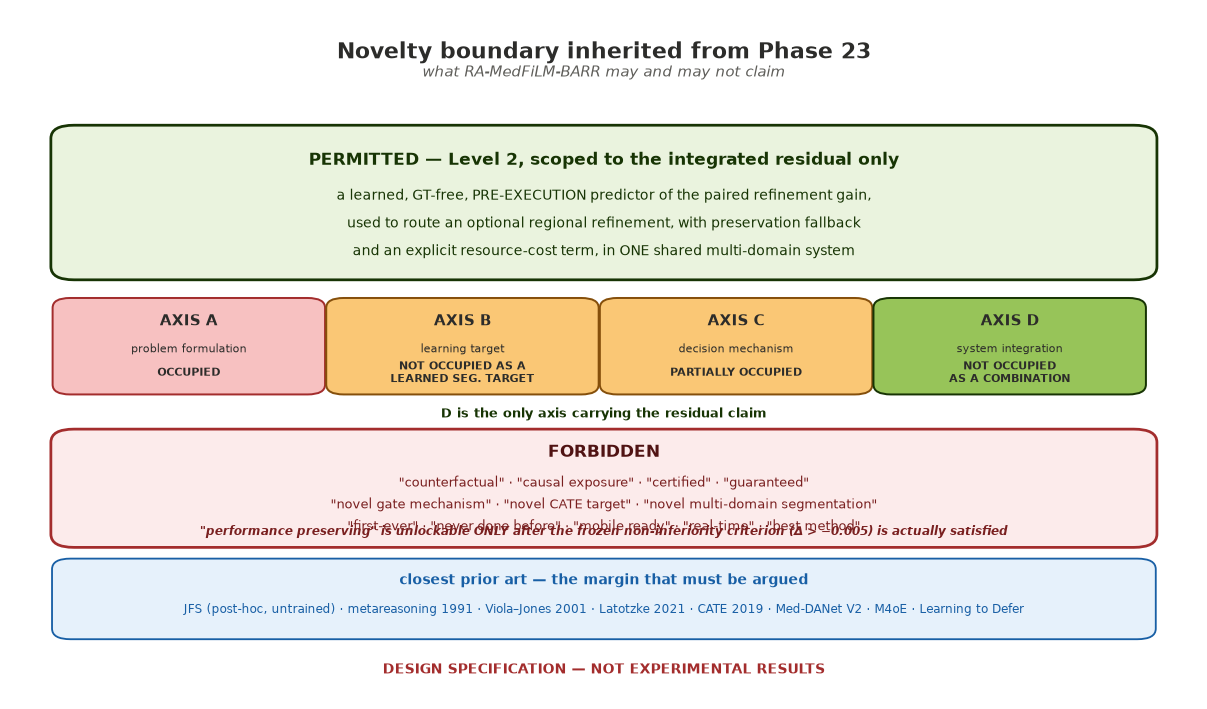

In [35]:
fig("p24_novelty_boundary.png",
    "Figure 6 — Novelty boundary (DESIGN SPECIFICATION — NOT EXPERIMENTAL RESULTS)")

## 32. Forbidden claims

No document produced under this specification may use any of the following until the corresponding
preregistered criterion is actually met.

In [36]:
fc = arch.get("forbidden_claims", [])
print(f"forbidden claims ({len(fc)}):")
for c in fc:
    print("   -", c)
print()
print("current allowed wording:", arch.get("current_allowed_wording"))
print("level-2 condition     :", arch.get("level_2_wording_condition"))

forbidden claims (16):
   - first-ever
   - first in the world
   - never done before
   - counterfactual causal effect
   - certified
   - guaranteed
   - novel value-of-computation
   - novel gating mechanism
   - novel CATE target
   - novel multi-domain segmentation
   - novel tiny-lesion segmentation
   - mobile ready
   - real-time
   - resource optimal
   - best method
   - performance preserving (until the frozen non-inferiority criterion is actually met)

current allowed wording: We specify a benefit-aware refinement-routing system...
level-2 condition     : Future Level-2 wording may be used only after empirical support and only for the exact integrated contribution identified by Phase 23.


## 33. Design figures — all marked "DESIGN SPECIFICATION — NOT EXPERIMENTAL RESULTS"

Six figures, all declared in `phase24_figure_manifest.json` with
`contains_experimental_results: False` and `contains_hypothetical_performance_curves: False`.

In [37]:
fm = _j(FIG / "phase24_figure_manifest.json")
print("classification     :", fm.get("classification"))
print("contains_experimental_results:", fm.get("contains_experimental_results"))
print("contains_hypothetical_curves :", fm.get("contains_hypothetical_performance_curves"))
print("n_figures          :", fm.get("n_figures"))
print()
for name, meta in fm.get("figures", {}).items():
    print(f"  {name:44s} {meta.get('bytes'):>7}B  {meta.get('sha256')[:16]}")

classification     : DESIGN_SPECIFICATION_FIGURES
contains_experimental_results: False
contains_hypothetical_curves : False
n_figures          : 6

  p24_full_system_architecture.png              113117B  d152887addc1c0f3
  p24_pre_gate_vs_post_safety.png               100990B  d4e37c91bce4fcb0
  p24_train_router_holdout_flow.png              99650B  470e8f58a459223c
  p24_crossfit_gain_label_generation.png         58991B  f384894839aa4bcc
  p24_resource_budget_evaluation.png             72730B  044413d7193dc360
  p24_novelty_boundary.png                      112731B  566f7cc14f2ac886


## 34. No-execution audit, verified from inside the notebook

The counters below are asserted to be zero. If any counter were non-zero the notebook would fail.

In [38]:
ne = _j(AUD / "phase24_no_execution_audit.json")
counters = {k: v for k, v in ne.items()
            if isinstance(v, int) and ("count" in k or "reads" in k or "runs" in k
                                       or "calls" in k or "passes" in k or "inference" in k
                                       or "training" in k)}
print("no-execution counters:")
for k, v in sorted(counters.items()):
    print(f"  {k:34s} {v}")
print()
nonzero = {k: v for k, v in counters.items() if v != 0}
print("non-zero counters  :", nonzero)
assert not nonzero, f"FAIL-CLOSED: non-zero execution counters: {nonzero}"
print("ALL COUNTERS ZERO: PASS")
print()
print("verdict:", ne.get("verdict"))

no-execution counters:
  backward_passes                    0
  benefit_router_inference_calls     0
  refinement_forward_passes          0
  segmentation_inference_calls       0
  test_image_reads                   0
  test_inference_calls               0
  test_mask_reads                    0
  test_reads                         0
  training_runs                      0
  val_outcome_reads                  0

non-zero counters  : {}
ALL COUNTERS ZERO: PASS

verdict: PHASE24_NO_EXECUTION_AUDIT_PASS


---
# Exact implementation pre-registration addendum

### POST-PHASE24 SPECIFICATION-COMPLETENESS REPAIR

**DESIGN SPECIFICATION — NO TRAINING PERFORMED**

This addendum closes the remaining implementation degrees of freedom **before** Phase 25, so
Phase 25 cannot silently choose architecture or protocol based on observed performance. It is
a `SPECIFICATION_COMPLETENESS_REPAIR` — **not** an architecture search and **not** a Phase-25
implementation.

| Item | Value |
|---|---|
| Architecture revision | `ra_medfilm_barr_narrowed_v1_1` (supersedes `…_v1`; **SPECIFICATION_COMPLETENESS_ONLY**) |
| Method name | `RA-MedFiLM-BARR` — **unchanged**, not a new method |
| Science changed | **NO** |
| Split seed | `MASTER_DEVELOPMENT_SEED = 42` |
| Training | **NONE** · Module instantiation: **NONE** · Forward passes: **NONE** |
| Holdout outcomes read | **0** · VAL outcome reads: **0** · TEST: **CLOSED** |

## A.1 Frozen split seed and materialized split

**`MASTER_DEVELOPMENT_SEED = 42`** is frozen now. No pre-existing repository split with a
different seed was found, so the default applies and no superseding seed is recorded. Seed 42
drives the development/holdout split, the 3-fold refiner cross-fitting, the router-internal
ordering and the pre-registered bootstrap. It matches the project-wide
`configs/research_protocol.json` seed policy and the Phase-21 seed42 `clean_v3` run.

**Group key.** `patient_id` is a *real* identifier only for KUB (318 patients). BUSI, ISIC and
KVASIR carry `patient_id == "NOT_AVAILABLE"`, so for them the group key falls back to the
leakage-safe duplicate ledger, else a per-sample singleton. This composite key is the only
defensible leakage-safe grouping available.

In [39]:
pe = _j(AUD / "phase24_benefit_data_protocol_exact.json")
print("master development seed :", pe.get("split_seed"))
print("split algorithm         :", pe.get("split_algorithm")[:110], "...")
print("stratification key      :", pe.get("stratification_key"))
print()
print("development n           :", pe.get("development_n"))
print("holdout n               :", pe.get("holdout_n"))
print("total n                 :", pe.get("total_n"))
print("holdout fraction        :", pe.get("holdout_fraction_realized"))
print()
print("domain counts (dev/hold/total):")
for dom, c in (pe.get("domain_counts") or {}).items():
    print(f"   {dom:8s} {c['development']:5d} / {c['holdout']:4d} / {c['total']:5d}")
print()
print("zero overlap (dev & hold):", pe.get("zero_overlap"))
print("zero overlap (group)     :", pe.get("zero_overlap_group_level"))
print("VAL overlap zero         :", pe.get("phase22_val_overlap_zero"))
print("TEST overlap zero        :", pe.get("test_overlap_zero"))
print("deterministic recheck    :", pe.get("deterministic_recheck"))
print("split manifest sha256    :", pe.get("manifest_sha256"))
print("holdout outcomes read    :", pe.get("holdout_outcomes_read"))
assert pe.get("zero_overlap") and pe.get("phase22_val_overlap_zero") and pe.get("test_overlap_zero")
assert pe.get("holdout_outcomes_read") == 0

master development seed : 42
split algorithm         : Per domain: group rows by the composite group key; sort groups by sha256('42::<group_key>'); greedily assign w ...
stratification key      : dataset (domain); 4 strata = BUSI, ISIC, KUB, KVASIR

development n           : 4957
holdout n               : 875
total n                 : 5832
holdout fraction        : 0.150034

domain counts (dev/hold/total):
   BUSI       512 /   90 /   602
   ISIC      2173 /  383 /  2556
   KUB       1680 /  298 /  1978
   KVASIR     592 /  104 /   696

zero overlap (dev & hold): True
zero overlap (group)     : True
VAL overlap zero         : True
TEST overlap zero        : True
deterministic recheck    : True
split manifest sha256    : b5da52d6220ef9b59b4ba70d0b403b38bf5234b897615b6ad55d718114db6555
holdout outcomes read    : 0


## A.2 Exact primary ROI rule

| Constant | Frozen value |
|---|---|
| Predicted-foreground threshold | `0.30` |
| Expansion factor | **`1.50`** (≡ fractional margin `0.25`, the inherited `ORACLE_DERIVED_REFINER_MARGIN`) |
| Regional input resolution | **`256 × 256`** |
| Image / probability resize | bilinear |
| GT mask resize (training target only) | nearest |
| Empty global prediction | **`FORCED_SKIP`** (no GT rescue) |

The 1.50× factor is inherited from the already-declared Phase-22 regional geometry, preserving
comparability. `256` is a **prospective design choice**, not a claim that 256 is optimal. No
TRAIN/VAL sweep over ROI scale is permitted in the primary method.

In [40]:
ex = _j(AUD / "phase24_exact_implementation_spec.json")
roi = ex.get("roi", {})
print("expansion factor        :", roi.get("expansion_factor"))
print("fractional margin       :", roi.get("fractional_margin_equivalent"),
      f"({roi.get('margin_constant_name')} = {roi.get('margin_constant_value')})")
print("margin constant source  :", roi.get("margin_constant_source"))
print("input resolution        :", roi.get("input_resolution"))
print("resize modes            :", roi.get("resize_modes"))
print("empty prediction        :", roi.get("empty_prediction_behavior"))
print("gt rescue               :", roi.get("gt_rescue"))
print("roi scale sweep primary :", roi.get("train_val_sweep_over_roi_scale_in_primary"))

expansion factor        : 1.5
fractional margin       : 0.25 (ORACLE_DERIVED_REFINER_MARGIN = 0.25)
margin constant source  : src/data/regional_dataset.py:22
input resolution        : 256
resize modes            : {'image': 'bilinear', 'probability_map': 'bilinear', 'gt_mask_training_target_only': 'nearest'}
empty prediction        : FORCED_SKIP
gt rescue               : False
roi scale sweep primary : False


## A.3 Exact regional refiner architecture — `BARRRegionalRefinerV1`

| Property | Value |
|---|---|
| Input | 4 channels `[R, G, B, p_global_crop]` |
| Output | 1-channel logits |
| Resolution | 256 × 256 |
| Encoder/bridge channels (**declared**) | `[16, 32, 64, 128, 192]` |
| Encoder/bridge channels (**active**) | `[16, 32, 64, 96, 128]` |
| Downsample | max-pool 2×2 · Upsample: bilinear ×2 · Skip: concatenate |
| Norm / activation | GroupNorm (≤8 groups) / SiLU · conv `bias=False` before GroupNorm |
| Forbidden | dropout, attention, SE, transformer, deep supervision, pretrained weights |
| Task conditioning (FiLM) | **NO** — keeps `R_psi` simple; future ablation only |

**Deterministic envelope resolution (declared BEFORE training).** The declared channels compute
to **2,317,553** parameters — which **exceeds** the 2,000,000 hard ceiling. Without consulting
any outcome, the pre-declared deterministic reduction `[16,32,64,96,128]` is adopted, giving
**1,276,401** parameters, inside the recommended 0.5M–1.5M envelope. Channels may **not** be
changed after observing performance.

In [41]:
rf = ex.get("refiner", {})
print("name                    :", rf.get("name"))
print("input / output          :", rf.get("input_channels"), "->", rf.get("output_channels"),
      rf.get("output_kind"))
print("declared channels       :", rf.get("encoder_bridge_channels_declared"))
print("active channels         :", rf.get("encoder_bridge_channels_active"))
print("declared closed-form    :", f"{rf.get('expected_parameter_count_declared_channels'):,}")
print("active closed-form      :", f"{rf.get('expected_parameter_count_closed_form'):,}")
print("hard ceiling            :", f"{rf.get('hard_ceiling'):,}")
print("within hard ceiling     :", rf.get("envelope_within_ceiling"))
print("within recommended band :", rf.get("envelope_within_recommended"))
print("envelope reduction?     :", rf.get("envelope_reduction_applied"))
print()
print("alternatives considered:")
for k, v in (rf.get("envelope_reduction_alternatives_considered") or {}).items():
    print(f"   {k:34s} {v:,}")
print()
print("forbidden components    : dropout", rf.get("dropout"), "| attention", rf.get("attention"),
      "| SE", rf.get("se_blocks"), "| transformer", rf.get("transformer"),
      "| deep-sup", rf.get("deep_supervision"), "| pretrained", rf.get("pretrained_weights"))
print("task conditioning FiLM  :", rf.get("task_conditioning_film"))

name                    : BARRRegionalRefinerV1
input / output          : 4 -> 1 logits
declared channels       : [16, 32, 64, 128, 192]
active channels         : [16, 32, 64, 96, 128]
declared closed-form    : 2,317,553
active closed-form      : 1,276,401
hard ceiling            : 2,000,000
within hard ceiling     : True
within recommended band : True
envelope reduction?     : True

alternatives considered:
   [16,32,64,128,192] one_block       2,317,553
   [16,32,64,128,192] two_block       2,710,193
   [16,32,64,96,128] one_block        1,276,401
   [16,32,64,96,128] two_block        1,539,889

forbidden components    : dropout False | attention False | SE False | transformer False | deep-sup False | pretrained False
task conditioning FiLM  : False


## A.4 Exact refiner training protocol and nested cross-fit roles

| Setting | Value |
|---|---|
| Loss | `0.5 * BCEWithLogits + 0.5 * soft Dice` |
| Optimizer / LR / WD | AdamW / `1e-4` / `1e-4` |
| Scheduler | cosine annealing |
| Max epochs / patience | 100 / 15 |
| Batch size / AMP | 8 / enabled when supported |
| Seed | 42 |
| Checkpoint selection | **lowest validation loss** (Dice = secondary diagnostic) |

**The nested role is the decisive point.** The held-out (OOF target) fold may be used **only**
for OOF prediction/label creation, **never** for checkpoint selection. Early stopping therefore
runs against a deterministic **TRAIN-INTERNAL 90/10 fitting/early-stop split** created inside
each refiner-training portion — group-safe, domain-stratified, seed 42. The OOF target fold
stays untouched until prediction.

In [42]:
cf = ex.get("crossfit", {})
print("outer folds            :", cf.get("outer_folds"))
print("within                 :", cf.get("within"))
print("inner fitting fraction :", cf.get("inner_fitting_fraction"))
print("inner early-stop frac  :", cf.get("inner_early_stop_fraction"))
print("inner split rules      :", cf.get("inner_split_rules"))
print("oof fold role          :", cf.get("oof_fold_role"))
print("infer once per fold    :", cf.get("infer_once_per_fold"))
print("no training on fold before OOF:", cf.get("no_training_on_fold_before_oof_produced"))
print()
print("refiner training protocol:")
for k in ("loss", "optimizer", "lr", "weight_decay", "scheduler", "max_epochs",
          "early_stopping_patience", "batch_size", "seed", "checkpoint_selection"):
    print(f"   {k:24s} {rf.get(k)}")

outer folds            : 3
within                 : ROUTER_DEVELOPMENT
inner fitting fraction : 0.9
inner early-stop frac  : 0.1
inner split rules      : ['group-safe', 'domain-stratified', 'seed 42']
oof fold role          : UNTOUCHED until prediction, then used only for OOF gain labels
infer once per fold    : True
no training on fold before OOF: True

refiner training protocol:
   loss                     0.5 * BCEWithLogits + 0.5 * soft Dice
   optimizer                AdamW
   lr                       0.0001
   weight_decay             0.0001
   scheduler                cosine annealing
   max_epochs               100
   early_stopping_patience  15
   batch_size               8
   seed                     42
   checkpoint_selection     lowest validation loss (primary); Dice recorded as secondary diagnostic only


## A.5 Final deployment refiner rule — `R_psi_final`

This was previously underspecified. It is now frozen:

1. The three OOF refiner runs produce gain labels.
2. Determine the final training duration prospectively as the **median integer best epoch** of
   the three OOF refiner runs.
3. **Reinitialize** `BARRRegionalRefinerV1` from **seed 42**.
4. Train on **all executable-action `ROUTER_DEVELOPMENT` samples** for **exactly** that many
   epochs, using the frozen optimizer/loss/scheduler.

**No early stopping on `ROUTER_HOLDOUT`.** `R_psi_final` is the **only** regional refiner used
for ROUTER_HOLDOUT evaluation, later continuity VAL evaluation, and future Phase 26+ development.
This prevents arbitrary selection among the three fold refiners.

In [43]:
fr = ex.get("final_refiner", {})
print("name                   :", fr.get("name"))
print("refit rule             :", fr.get("refit_rule"))
print("data allowed           :", fr.get("data_allowed"))
print("holdout forbidden      :", fr.get("holdout_forbidden"))
print("holdout for ckpt sel   :", fr.get("holdout_for_checkpoint_selection"))
print("epoch rule             :", fr.get("epoch_rule"))
print("early stop on holdout  :", fr.get("early_stopping_on_holdout"))
print("arbitrary fold pick    :", fr.get("arbitrary_fold_refiner_selection_forbidden"))

name                   : R_psi_final
refit rule             : after the three OOF refiner runs have produced gain labels, train ONE final regional refiner on ALL executable-action ROUTER_DEVELOPMENT samples
data allowed           : all executable-action ROUTER_DEVELOPMENT samples
holdout forbidden      : True
holdout for ckpt sel   : False
epoch rule             : reinitialize BARRRegionalRefinerV1 from seed 42 and train for exactly the median integer best epoch of the three OOF refiner runs (prospectively determined)
early stop on holdout  : False
arbitrary fold pick    : True


## A.6 Frozen global feature taps and primary router feature set

**Taps** (from the frozen Phase-21 Global MedFiLM, reusing the *same* forward — a second global
forward is forbidden):

`bridge` · `decoder2` · `decoder1` — each summarised by a **global average pool** and an
**ROI-aware average pool** mapped to that feature grid. No trainable convolutional projection
before pooling.

Every requested scalar name is mapped to its **exact authoritative** feature in the frozen
contract (`phase24_router_input_contract.csv`). No literal is silently invented.

In [44]:
fs = pd.read_csv(TAB / "phase24_router_primary_feature_set.csv")
print(f"primary feature set: {len(fs)} rows")
print("mapping kinds:", fs["mapping_kind"].value_counts().to_dict())
print()
# FAIL-CLOSED: no mapped feature may use GT or be post-refinement
_bad = fs[(fs["uses_GT"].astype(str).str.lower() != "false")
          | (fs["available_pre_refinement"].astype(str).str.lower() != "true")
          | (fs["inference_available"].astype(str).str.lower() != "true")]
print("rows violating GT-free/pre-refinement:", len(_bad))
assert len(_bad) == 0, "FAIL-CLOSED: a primary feature is not GT-free/pre-refinement"
assert (fs["resource_cost_enters_delta_hat"].astype(str).str.lower() == "false").all()
display(sty(fs[["requested_literal", "group", "contract_feature", "mapping_kind"]],
            "p24-primary-features"))

primary feature set: 17 rows
mapping kinds: {'DIRECT': 6, 'DIRECT_EQUIVALENT': 4, 'DERIVED': 4, 'SHARED_AXIS': 3}

rows violating GT-free/pre-refinement: 0


,requested_literal,group,contract_feature,mapping_kind
0,bridge_global_pool,tap,global_encoder_pooled_features,DIRECT
1,bridge_roi_pool,tap,roi_pooled_global_features,DIRECT
2,decoder2_global_pool,tap,global_decoder_pooled_features,DIRECT
3,decoder2_roi_pool,tap,roi_pooled_global_features,SHARED_AXIS
4,decoder1_global_pool,tap,global_decoder_pooled_features,SHARED_AXIS
5,decoder1_roi_pool,tap,roi_pooled_global_features,SHARED_AXIS
6,entropy_proxy_mean,scalar,probability_entropy_summaries,DIRECT_EQUIVALENT
7,frac_prob_within_0p05_of_boundary,scalar,predicted_boundary_area_statistics,DIRECT_EQUIVALENT
8,frac_prob_within_0p02_of_boundary,scalar,predicted_boundary_area_statistics,DIRECT_EQUIVALENT
9,mean_boundary_margin,scalar,probability_margin_summaries,DIRECT_EQUIVALENT


## A.7 Exact router architecture — `BARRBenefitRouterV1`

| Property | Value |
|---|---|
| Input | concatenated fixed feature vector (`§A.6`) |
| Task embedding | 4 tasks → dim **16** |
| Scalar normalisation | mean/std from **ROUTER_DEVELOPMENT only** |
| Hidden dims (declared → active) | `[128, 64]` → `[128, 64]` (no reduction needed) |
| Architecture | `Linear(in,128) → LayerNorm → SiLU → Dropout(0.10) → Linear(128,64) → LayerNorm → SiLU → Dropout(0.10) → Linear(64,1)` |
| Output | `Delta_hat_Dice` (single continuous scalar) |
| Harm head | **NOT** in the primary router (pre-registered extension only) |

Keeping the primary router single-head prevents the scientific hypothesis from being confounded
by multi-task training. Resource cost **must not** enter `Delta_hat`; it enters `U_hat` separately.

In [45]:
rt = ex.get("router", {})
print("name                     :", rt.get("name"))
print("feature taps             :", rt.get("feature_taps"))
print("input dim (closed form)  :", rt.get("input_dim_closed_form"))
print("breakdown                :", rt.get("input_dim_breakdown"))
print("task embedding           :", rt.get("task_conditioning"))
print("normalisation            :", rt.get("normalization"))
print("norm from holdout?       :", rt.get("normalization_from_holdout_val_test"))
print("hidden declared -> active:", rt.get("hidden_dimensions_declared"), "->",
      rt.get("hidden_dimensions_active"))
print("closed-form params       :", f"{rt.get('expected_parameter_count_closed_form'):,}")
print("max parameters           :", f"{rt.get('max_parameters'):,}")
print("within ceiling           :", rt.get("envelope_within_ceiling"))
print("reduction applied        :", rt.get("envelope_reduction_applied"))
print("harm head                :", rt.get("harm_head"))
print("resource cost in Delta   :", rt.get("resource_cost_enters_delta_hat"))

name                     : BARRBenefitRouterV1
feature taps             : ['bridge', 'decoder2', 'decoder1']
input dim (closed form)  : 218
breakdown                : {'tap_axes': 6, 'tap_axes_x_width': 192, 'scalars': 10, 'task_embedding': 16}
task embedding           : {'n_tasks': 4, 'embedding_dim': 16, 'task_id_mapping': {'ISIC': 0, 'BUSI': 1, 'KVASIR': 2, 'KUB': 3}}
normalisation            : mean/std computed on ROUTER_DEVELOPMENT only for scalar continuous descriptors
norm from holdout?       : FORBIDDEN
hidden declared -> active: [128, 64] -> [128, 64]
closed-form params       : 36,353
max parameters           : 250,000
within ceiling           : True
reduction applied        : False
harm head                : NOT part of the primary router; pre-registered extension only
resource cost in Delta   : False


## A.8 Router training protocol, routing thresholds and lambda grid

| Setting | Value |
|---|---|
| Target | continuous OOF `DeltaDice` |
| Loss | **Huber, delta = 0.05** (robust to extreme harmed/improved cases) |
| Optimizer / LR / WD | AdamW / `1e-3` / `1e-4` |
| Batch / max epochs / patience | 128 / 200 / 20 |
| Scheduler | `ReduceLROnPlateau(factor=0.5, patience=8, min_lr=1e-6)` |
| Epoch selection | deterministic **5-fold** group-safe CV inside `ROUTER_DEVELOPMENT` OOF rows |

**Routing.** Primary score `score_i = Delta_hat_Dice_i`. Fixed-budget thresholds (10 / 25 / 50%)
come from **`ROUTER_DEVELOPMENT` score quantiles only**. 0% = global-only; 100% = all
action-available samples refine.

**Utility.** `U_hat = Delta_hat − λ·C`, with a **frozen prospective λ grid `{0.0, 0.25, 0.5, 1.0}`**
and `C` the normalized incremental *analytical* MAC cost. λ is never searched on holdout outcomes.

In [46]:
print("router training protocol:")
for k in ("loss", "loss_reason", "optimizer", "lr", "weight_decay", "batch_size",
          "max_epochs", "early_stopping_patience", "scheduler", "seed", "epoch_selection"):
    print(f"   {k:26s} {rt.get(k)}")
print()
rg = ex.get("routing", {})
print("routing score            :", rg.get("score"))
print("budgets                  :", rg.get("budgets"))
print("threshold source         :", rg.get("threshold_source"))
print("lambda grid              :", rg.get("lambda_grid"))
print("cost definition          :", rg.get("cost_definition"))
print("cost scale derivation    :", rg.get("cost_scale_derivation"))
print("single universal lambda  :", rg.get("single_universal_lambda_forbidden"))

router training protocol:
   loss                       Huber loss, delta = 0.05
   loss_reason                paired gain can contain extreme harmed/improved cases; Huber is robust while preserving continuous-gain supervision
   optimizer                  AdamW
   lr                         0.001
   weight_decay               0.0001
   batch_size                 128
   max_epochs                 200
   early_stopping_patience    20
   scheduler                  ReduceLROnPlateau(factor=0.5, patience=8, min_lr=1e-6)
   seed                       42
   epoch_selection            deterministic 5-fold group-safe cross-validation inside ROUTER_DEVELOPMENT OOF gain rows

routing score            : score_i = Delta_hat_Dice_i
budgets                  : ['0%', '10%', '25%', '50%', '100%']
threshold source         : ROUTER_DEVELOPMENT quantiles only
lambda grid              : [0.0, 0.25, 0.5, 1.0]
cost definition          : normalized incremental analytical MAC cost
cost scale derivation    : a

## A.9 Cross-fit / refit diagram and addendum figure

The design below shows the full nested procedure: three outer OOF folds (each with its own
internal 90/10 early-stop split), the gain-label concat, and the single final refit on all
`ROUTER_DEVELOPMENT` data at the median selected epoch count.

In [47]:
# deterministic inline ASCII diagram of the cross-fit / refit procedure (no figure asset needed)
print("""
ROUTER_DEVELOPMENT (4957, group-safe, domain-stratified, seed 42)
├── OUTER FOLD 0 ──► fit R_psi on folds {1,2}   ├─ internal 90/10 fit/early-stop
│                     infer ONCE on fold 0  ────► OOF DeltaDice (fold 0)
├── OUTER FOLD 1 ──► fit R_psi on folds {0,2}   ├─ internal 90/10 fit/early-stop
│                     infer ONCE on fold 1  ────► OOF DeltaDice (fold 1)
└── OUTER FOLD 2 ──► fit R_psi on folds {0,1}   ├─ internal 90/10 fit/early-stop
                      infer ONCE on fold 2  ────► OOF DeltaDice (fold 2)
                     │
   concat executable-action OOF rows ──► B_phi fitted on OOF DeltaDice
                     │
   median best epoch of the 3 OOF runs = N_median
                     │
   R_psi_final : reinit seed 42, train on ALL ROUTER_DEVELOPMENT, exactly N_median epochs
                     │
   ROUTER_HOLDOUT (875) : integrated evaluation ONLY, never for fitting or epoch selection
""")


ROUTER_DEVELOPMENT (4957, group-safe, domain-stratified, seed 42)
├── OUTER FOLD 0 ──► fit R_psi on folds {1,2}   ├─ internal 90/10 fit/early-stop
│                     infer ONCE on fold 0  ────► OOF DeltaDice (fold 0)
├── OUTER FOLD 1 ──► fit R_psi on folds {0,2}   ├─ internal 90/10 fit/early-stop
│                     infer ONCE on fold 1  ────► OOF DeltaDice (fold 1)
└── OUTER FOLD 2 ──► fit R_psi on folds {0,1}   ├─ internal 90/10 fit/early-stop
                      infer ONCE on fold 2  ────► OOF DeltaDice (fold 2)
                     │
   concat executable-action OOF rows ──► B_phi fitted on OOF DeltaDice
                     │
   median best epoch of the 3 OOF runs = N_median
                     │
   R_psi_final : reinit seed 42, train on ALL ROUTER_DEVELOPMENT, exactly N_median epochs
                     │
   ROUTER_HOLDOUT (875) : integrated evaluation ONLY, never for fitting or epoch selection



## A.10 Post-safety, fusion and action availability

**`BARRPostSafetyV1`** is a `CONTROLLED_CORE_EXTENSION` used **only** in A8. The primary novelty
evaluation is A7 — the benefit + resource gate **without** post-safety. It saves **zero** compute
and must never be presented as the compute-saving mechanism (JFS differentiation remains
mandatory). Architecture `input → 32 → 16 → 1` small MLP, BCE loss, target *ACCEPT iff
`DeltaDice > 0`*, features from already-computed post-refinement quantities only, no GT at
inference, no second image encoder.

**Fusion** is exact and unlearned: outside the frozen ROI use `p_global`; inside use the resized
`p_refined`. No alpha blending, no learned fusion, segmentation threshold **`0.5`** inherited,
no threshold tuning.

**Action availability** `definition = predicted ROI exists`. When the global prediction is empty:
`action_available = false`, pre-gate is `FORCED_SKIP`, final is `global`. Such samples stay in the
integrated evaluation, receive **no** synthetic GT ROI and **no** fabricated gain target, and are
excluded from regression training rows, reported as `ACTION_UNAVAILABLE_GLOBAL_EMPTY`. This
separates *"predicted negative benefit"* from *"no legal refinement action exists."*

In [48]:
ps = ex.get("post_safety", {})
fu = ex.get("fusion", {})
aa = ex.get("action_availability", {})
print("post-safety name         :", ps.get("name"))
print("extension status         :", ps.get("extension_status"))
print("primary evaluation       :", ps.get("primary_evaluation"))
print("saves compute            :", ps.get("saves_compute"))
print("architecture             :", ps.get("architecture"))
print("gt at inference          :", ps.get("gt_at_inference"))
print()
print("fusion rule              :", fu.get("rule"))
print("alpha blending           :", fu.get("alpha_blending"))
print("learned fusion           :", fu.get("learned_fusion"))
print("segmentation threshold   :", fu.get("segmentation_threshold"),
      f"({fu.get('segmentation_threshold_source')})")
print()
print("action_available         :", aa.get("definition"))
print("global-empty pre-gate    :", aa.get("global_empty_pre_gate"))
print("global-empty final       :", aa.get("global_empty_final"))
print("global-empty report label:", aa.get("global_empty_report_label"))
assert ps.get("saves_compute") is False
assert fu.get("segmentation_threshold") == 0.5
assert aa.get("global_empty_pre_gate") == "FORCED_SKIP"

post-safety name         : BARRPostSafetyV1
extension status         : CONTROLLED_CORE_EXTENSION
primary evaluation       : A7 / benefit + resource gate WITHOUT post-safety
saves compute            : False
architecture             : input -> 32 -> 16 -> 1 (sigmoid/logit)
gt at inference          : False

fusion rule              : outside frozen ROI: p_final_candidate = p_global; inside frozen ROI: p_final_candidate = resized p_refined
alpha blending           : False
learned fusion           : False
segmentation threshold   : 0.5 (INHERITED)

action_available         : action_available_i = predicted ROI exists
global-empty pre-gate    : FORCED_SKIP
global-empty final       : global
global-empty report label: ACTION_UNAVAILABLE_GLOBAL_EMPTY


## A.11 Module envelope and specification-integrity checks

Closed-form architecture arithmetic only — **no module is instantiated** to count parameters.

In [49]:
me = pd.read_csv(TAB / "phase24_spec_module_envelope.csv")
display(sty(me, "p24-spec-envelopes"))
print()
sch = pd.read_csv(TAB / "phase25_future_oof_gain_schema.csv")
print(f"OOF gain schema: {len(sch)} columns, SCHEMA ONLY (0 data rows)")
display(sty(sch[["column", "role", "uses_GT", "available_pre_refinement"]], "p24-oof-schema"))
print()
rp = rt.get("expected_parameter_count_closed_form")
rr = rf.get("expected_parameter_count_closed_form")
assert rr <= 2_000_000, "refiner exceeds hard ceiling"
assert rp <= 250_000, "router exceeds hard ceiling"
print(f"SPEC INTEGRITY: refiner {rr:,} <= 2,000,000  and router {rp:,} <= 250,000 : PASS")
print("DESIGN SPECIFICATION — NO TRAINING PERFORMED")

,module,name,declared_envelope,active_envelope,closed_form_params,within_hard_ceiling,measured,note
0,R_psi,BARRRegionalRefinerV1,"[16,32,64,128,192] one block/stage","[16,32,64,96,128] one block/stage",1276401,True,False,declared channels exceed 2.0M ceiling; deterministic pre-declared reduction applied
1,B_phi,BARRBenefitRouterV1,"hidden [128,64]","hidden [128,64]",36353,True,False,well within 250k ceiling; no reduction required
2,S_omega,BARRPostSafetyV1,input->32->16->1,input->32->16->1,closed_form_not_frozen_here,True,False,post-refinement extension; no second encoder
3,G,Frozen Global MedFiLM (Phase 21),3523001,3523001,3523001,nan,True,frozen anchor; measured in Phase 21



OOF gain schema: 11 columns, SCHEMA ONLY (0 data rows)


,column,role,uses_GT,available_pre_refinement
0,sample_id,key,False,True
1,dataset,stratum,False,True
2,task_id,conditioning,False,True
3,oof_fold,provenance,False,True
4,action_available,filter,False,True
5,dice_global,DERIVED_LABEL_COMPONENT,True,False
6,dice_refined_fused,DERIVED_LABEL_COMPONENT,True,False
7,delta_dice,TARGET,True,False
8,refiner_checkpoint_sha256,provenance,False,True
9,refiner_best_epoch,provenance,False,True



SPEC INTEGRITY: refiner 1,276,401 <= 2,000,000  and router 36,353 <= 250,000 : PASS
DESIGN SPECIFICATION — NO TRAINING PERFORMED


## 35. Notebook determinism contract

This notebook is built with the same determinism contract as Phases 21–23:

- fixed cell ids (`p24NNN`),
- stripped `metadata.execution`,
- coalesced stream outputs,
- fixed pandas Styler uuids,
- normalised object memory addresses (`0x…` → `0xADDR`).

The determinism *proof* (three byte-identical builds) is established by
`scripts/analysis/run_phase24_determinism.py` **after** the notebook is written — it cannot be
read from inside the notebook without creating a circular dependency. What the notebook asserts
here is that the contract *machinery* is present and that this build executed cleanly.

In [50]:
import nbformat as _nbf

_nb_path = pathlib.Path(
    r"D:/Softfors/jup/notebooks/phasewise/phase_24_architecture_spec/"
    r"phase24_narrowed_benefit_aware_refinement_spec.ipynb")
_nb = _nbf.read(str(_nb_path), as_version=4) if _nb_path.exists() else None
print("notebook path      :", _nb_path.name)
print("exists             :", _nb_path.exists())
print("determinism contract:")
for _c in ["fixed cell ids (p24NNN)",
           "stripped metadata.execution",
           "coalesced stream outputs",
           "fixed pandas Styler uuids (set_uuid)",
           "normalised 0x addresses"]:
    print("   -", _c)
print()
print("proof location     : scripts/analysis/run_phase24_determinism.py")
print("required builds    : 3 byte-identical")

notebook path      : phase24_narrowed_benefit_aware_refinement_spec.ipynb
exists             : True
determinism contract:
   - fixed cell ids (p24NNN)
   - stripped metadata.execution
   - coalesced stream outputs
   - fixed pandas Styler uuids (set_uuid)
   - normalised 0x addresses

proof location     : scripts/analysis/run_phase24_determinism.py
required builds    : 3 byte-identical


## 36. Terminal state

The spec's terminal state is emitted only if every assertion below holds. Any single failure would
produce `PHASE24_NARROWED_SPEC_BLOCKED__REDESIGN_REQUIRED` instead.

Every assertion below reads an artifact that exists **before** the notebook executes — no
circular dependency. The determinism proof and the final freeze are established afterwards by
`run_phase24_determinism.py` and `run_phase24_final_check.py`.

In [51]:
import re as _re

nb_here = pathlib.Path(
    r"D:/Softfors/jup/notebooks/phasewise/phase_24_architecture_spec/"
    r"phase24_narrowed_benefit_aware_refinement_spec.ipynb")
sha_here = hashlib.sha256(nb_here.read_bytes()).hexdigest() if nb_here.exists() else "n/a"

arch_f = _j(AUD / "phase24_architecture_spec.json")
ne_f = _j(AUD / "phase24_no_execution_audit.json")
fm_f = _j(FIG / "phase24_figure_manifest.json")

assertions = []

def chk(name, cond):
    assertions.append((name, bool(cond)))

chk("entry gate 27/27", gate.get("n_passed") == 27 and gate.get("n_failed") == 0)
chk("gate verdict pass", gate.get("verdict") == "PHASE24_ENTRY_GATE_PASS")
chk("arch status design-only", arch_f.get("status") == "DESIGN_ONLY_NOT_IMPLEMENTED")
chk("architecture id", arch_f.get("architecture_id") == "ra_medfilm_barr_narrowed_v1")
chk("method name frozen", arch_f.get("method_name") == "RA-MedFiLM-BARR")
chk("global params measured = 3523001", arch_f["global_reference"]["parameters"] == 3523001)
chk("refiner env unmeasured", arch_f["regional_refiner"]["target_parameter_envelope"]["measured"] is False)
chk("router env unmeasured", arch_f["benefit_router"]["target_parameter_envelope"]["measured"] is False)
chk("refiner hard ceiling 2.0M",
    arch_f["regional_refiner"]["target_parameter_envelope"]["hard_ceiling"] == 2_000_000)
chk("router pre_refinement", arch_f["benefit_router"]["pre_refinement"] is True)
chk("router gt_free", arch_f["benefit_router"]["gt_free"] is True)
chk("router max params <= 250k",
    arch_f["benefit_router"]["target_parameter_envelope"]["max_parameters"] <= 250_000)
chk("router MACs fraction <= 2%",
    arch_f["benefit_router"]["compute_envelope"]
    ["max_analytical_macs_fraction_of_one_global_forward"] <= 0.02)
chk("post-safety saves no compute", arch_f["post_safety"]["saves_compute"] is False)
chk("post-safety novelty false", arch_f["post_safety"]["novelty_claimed"] is False)
chk("post-safety controlled ext",
    arch_f["post_safety"]["classification"] == "CONTROLLED_CORE_EXTENSION")
chk("VAL reclassified secondary", "SECONDARY" in arch_f["VAL_role"]["role"])
chk("VAL not router training", arch_f["VAL_role"]["is_router_training_data"] is False)
chk("VAL not untouched holdout", arch_f["VAL_role"]["is_untouched_routing_holdout"] is False)
chk("TEST lock all zero",
    all(v == 0 for k, v in arch_f["TEST_lock"].items() if k != "status"))
chk("holdout outcomes read 0", arch_f["router_holdout_contract"]["outcomes_read_in_phase24"] == 0)
chk("router holdout ~875", arch_f["router_holdout_contract"]["approx_cases"] == 875)
chk("preservation margin 0.005",
    arch_f["preservation_margin"]["absolute_macro_domain_dice_margin"] == 0.005)
chk("statistics n_boot 2000", arch_f["statistics"]["n_boot"] == 2000)
chk("statistics seed 42", arch_f["statistics"]["seed"] == 42)
chk("statistics test not used", arch_f["statistics"]["test_used"] is False)
chk("crossfit 3 folds", arch_f["crossfit_contract"]["folds"] == 3)
chk("crossfit not executed", arch_f["crossfit_contract"]["executed_in_phase24"] is False)
chk("H1 load-bearing", arch_f["hypotheses"]["load_bearing"] == "H1")
chk("hypotheses not results", arch_f["hypotheses"]["status"] == "HYPOTHESES_NOT_RESULTS")
chk("single lambda forbidden",
    arch_f["pre_execution_gate"]["single_universal_lambda_forbidden"] is True)
chk("no training", arch_f.get("no_training") is True)
chk("no inference", arch_f.get("no_inference") is True)
chk("no implementation", arch_f.get("no_implementation") is True)
chk("phase25 not started", arch_f.get("phase25_started") is False)
chk("no-notebook-training", ne_f.get("training_runs") == 0)
chk("no-notebook-seg-inference", ne_f.get("segmentation_inference_calls") == 0)
chk("no-notebook-router-inference", ne_f.get("benefit_router_inference_calls") == 0)
chk("no-notebook-refinement", ne_f.get("refinement_forward_passes") == 0)
chk("no-notebook-models-instantiated", ne_f.get("models_instantiated") == 0)
chk("no-notebook-test", ne_f.get("test_image_reads") == 0 and ne_f.get("test_mask_reads") == 0)
chk("no-notebook-holdout-outcomes", ne_f.get("router_holdout_outcomes_read") == 0)
chk("no-execution verdict pass", ne_f.get("verdict") == "PHASE24_NO_EXECUTION_AUDIT_PASS")
chk("no-execution script scan clean",
    ne_f.get("static_scan", {}).get("total_training_constructs") == 0
    and ne_f.get("static_scan", {}).get("total_inference_constructs") == 0
    and ne_f.get("static_scan", {}).get("total_test_constructs") == 0)
chk("6 design figures", fm_f.get("n_figures") == 6)
chk("figures no results", fm_f.get("contains_experimental_results") is False)
chk("figures no hypothetical curves",
    fm_f.get("contains_hypothetical_performance_curves") is False)
chk("no phase25 artifact", not list(AUD.glob("phase25_*")))
chk("comparator C7 present",
    "C7" in pd.read_csv(TAB / "phase24_comparator_plan.csv")["comparator_id"].values)
chk("11 comparators", len(pd.read_csv(TAB / "phase24_comparator_plan.csv")) == 11)
chk("13 ablations", len(pd.read_csv(TAB / "phase24_ablation_plan.csv")) == 13)
chk("8 success/failure criteria (F1-F5, S1-S3)",
    len(pd.read_csv(TAB / "phase24_success_failure_criteria.csv")) == 8)
chk("7 modules 25A-25G",
    len(_j(AUD / "phase24_phase25_module_plan.json").get("modules", [])) == 7)
chk("module plan not started",
    _j(AUD / "phase24_phase25_module_plan.json").get("no_module_started") is True)
chk("forbidden tokens absent from name",
    _j(AUD / "phase24_method_naming_decision.json").get("forbidden_tokens_check", "").startswith("PASS"))

# ---- specification-completeness repair addendum ----
_ex = _j(AUD / "phase24_exact_implementation_spec.json")
_pe = _j(AUD / "phase24_benefit_data_protocol_exact.json")
_fs = pd.read_csv(TAB / "phase24_router_primary_feature_set.csv")
_sch = pd.read_csv(TAB / "phase25_future_oof_gain_schema.csv")
chk("ADDENDUM revision v1.1",
    _ex.get("architecture_id") == "ra_medfilm_barr_narrowed_v1_1")
chk("ADDENDUM science changed = false", _ex.get("science_changed") is False)
chk("ADDENDUM method name unchanged", _ex.get("method_name") == "RA-MedFiLM-BARR")
chk("ADDENDUM split seed frozen 42", _ex.get("split_seed") == 42)
chk("ADDENDUM split dev/hold counts",
    _pe.get("development_n") == 4957 and _pe.get("holdout_n") == 875)
chk("ADDENDUM split zero overlap",
    _pe.get("zero_overlap") and _pe.get("phase22_val_overlap_zero")
    and _pe.get("test_overlap_zero"))
chk("ADDENDUM split determinism", _pe.get("deterministic_recheck") is True)
chk("ADDENDUM holdout outcomes 0", _pe.get("holdout_outcomes_read") == 0)
chk("ADDENDUM ROI expansion 1.50", _ex["roi"]["expansion_factor"] == 1.50)
chk("ADDENDUM ROI resolution 256", _ex["roi"]["input_resolution"] == 256)
chk("ADDENDUM ROI forced skip", _ex["roi"]["empty_prediction_behavior"] == "FORCED_SKIP")
chk("ADDENDUM ROI no gt rescue", _ex["roi"]["gt_rescue"] is False)
chk("ADDENDUM refiner within ceiling", _ex["refiner"]["envelope_within_ceiling"] is True)
chk("ADDENDUM refiner closed-form params",
    _ex["refiner"]["expected_parameter_count_closed_form"] == 1_276_401)
chk("ADDENDUM refiner no FiLM", _ex["refiner"]["task_conditioning_film"] is False)
chk("ADDENDUM refiner no attention/SE/transformer",
    _ex["refiner"]["attention"] is False and _ex["refiner"]["se_blocks"] is False
    and _ex["refiner"]["transformer"] is False)
chk("ADDENDUM crossfit nested 90/10",
    _ex["crossfit"]["inner_fitting_fraction"] == 0.90
    and _ex["crossfit"]["inner_early_stop_fraction"] == 0.10)
chk("ADDENDUM oof never for ckpt selection",
    _ex["crossfit"]["oof_target_fold_never_used_for_checkpoint_selection"] is True)
chk("ADDENDUM final refiner no holdout",
    _ex["final_refiner"]["holdout_forbidden"] is True
    and _ex["final_refiner"]["early_stopping_on_holdout"] is False)
chk("ADDENDUM final refiner median epoch",
    "median" in _ex["final_refiner"]["epoch_rule"])
chk("ADDENDUM router taps frozen",
    _ex["router"]["feature_taps"] == ["bridge", "decoder2", "decoder1"])
chk("ADDENDUM router no second forward",
    _ex["router"]["second_global_forward"] is False)
chk("ADDENDUM router single head",
    "NOT part of the primary router" in _ex["router"]["harm_head"])
chk("ADDENDUM router within 250k", _ex["router"]["envelope_within_ceiling"] is True)
chk("ADDENDUM router Huber 0.05",
    "Huber" in _ex["router"]["loss"] and "0.05" in _ex["router"]["loss"])
chk("ADDENDUM router norm holdout forbidden",
    _ex["router"]["normalization_from_holdout_val_test"] == "FORBIDDEN")
chk("ADDENDUM lambda grid frozen",
    _ex["routing"]["lambda_grid"] == [0.0, 0.25, 0.5, 1.0])
chk("ADDENDUM thresholds from dev only",
    _ex["routing"]["threshold_source"] == "ROUTER_DEVELOPMENT quantiles only")
chk("ADDENDUM post-safety A8 only",
    _ex["post_safety"]["included_in"] == "A8"
    and _ex["post_safety"]["saves_compute"] is False)
chk("ADDENDUM fusion threshold 0.5",
    _ex["fusion"]["segmentation_threshold"] == 0.5
    and _ex["fusion"]["alpha_blending"] is False)
chk("ADDENDUM action availability frozen",
    _ex["action_availability"]["global_empty_pre_gate"] == "FORCED_SKIP")
chk("ADDENDUM augmentation inherited",
    _ex["augmentation"]["inherited_from"].startswith("src.data.transforms"))
chk("ADDENDUM feature set 17 rows", len(_fs) == 17)
chk("ADDENDUM feature set all GT-free",
    all(_fs["uses_GT"].astype(str).str.lower() == "false")
    and all(_fs["available_pre_refinement"].astype(str).str.lower() == "true"))
chk("ADDENDUM resource cost not in Delta",
    all(_fs["resource_cost_enters_delta_hat"].astype(str).str.lower() == "false"))
chk("ADDENDUM OOF schema 11 cols", len(_sch) == 11)
chk("ADDENDUM no architecture search", _ex.get("no_architecture_search_allowed") is True)
chk("ADDENDUM no training", _ex.get("training_runs") == 0
    and _ex.get("module_instantiations") == 0 and _ex.get("forward_passes") == 0)
chk("ADDENDUM v1.1 revision artifact",
    _j(AUD / "phase24_architecture_revision_v1_1.json")
    .get("architecture_id") == "ra_medfilm_barr_narrowed_v1_1")

n_fail = sum(1 for _, ok in assertions if not ok)
for name, ok in assertions:
    print(f"  [{'PASS' if ok else 'FAIL'}] {name}")
print()
print(f"{len(assertions) - n_fail}/{len(assertions)} terminal assertions passed")
print()
print("Notebook SHA (pre-determinism-proof):", sha_here)
print()
print("PHASE24_NARROWED_BENEFIT_AWARE_REFINEMENT_SPEC_COMPLETE__PHASE25_ELIGIBLE_NOT_STARTED")
assert n_fail == 0, f"{n_fail} terminal assertion(s) failed"

  [PASS] entry gate 27/27
  [PASS] gate verdict pass
  [PASS] arch status design-only
  [PASS] architecture id
  [PASS] method name frozen
  [PASS] global params measured = 3523001
  [PASS] refiner env unmeasured
  [PASS] router env unmeasured
  [PASS] refiner hard ceiling 2.0M
  [PASS] router pre_refinement
  [PASS] router gt_free
  [PASS] router max params <= 250k
  [PASS] router MACs fraction <= 2%
  [PASS] post-safety saves no compute
  [PASS] post-safety novelty false
  [PASS] post-safety controlled ext
  [PASS] VAL reclassified secondary
  [PASS] VAL not router training
  [PASS] VAL not untouched holdout
  [PASS] TEST lock all zero
  [PASS] holdout outcomes read 0
  [PASS] router holdout ~875
  [PASS] preservation margin 0.005
  [PASS] statistics n_boot 2000
  [PASS] statistics seed 42
  [PASS] statistics test not used
  [PASS] crossfit 3 folds
  [PASS] crossfit not executed
  [PASS] H1 load-bearing
  [PASS] hypotheses not results
  [PASS] single lambda forbidden
  [PASS] no trai

## Router feature-spec completeness addendum — v1.2

**Classification:** `SPECIFICATION_COMPLETENESS_ONLY` · **science_changed:** `false`
**Revision:** `ra_medfilm_barr_narrowed_v1_2` (router-feature spec only)
**Method:** `RA-MedFiLM-BARR` — unchanged. Phase25A is NOT invalidated; `R_psi` is NOT retrained.

This addendum is the current **design-spec pointer**. The prior v1.1 notebook content above,
and the v1.1 freeze artifacts, remain historical provenance.

---

### Why Phase25B stopped

Phase25B (GT-free pre-refinement feature extraction) reached its fail-closed entry gate
(**22/22 PASS**) and then stopped with `PHASE25B_BLOCKED__FROZEN_FEATURE_SPEC_INCOMPLETE`.
The frozen Phase24 v1.1 artifacts fixed the router's **output** dimensionality but left three
implementation contracts underspecified. Phase25B is forbidden to invent them, so it stopped
rather than choose silently.


### The core finding — declared width vs native width

v1.1 froze `pool_width_per_axis = 32` and `input_dim_closed_form = 218`
(`6 × 32 + 10 + 16`). The arithmetic is internally consistent. What was **missing** is the
operation that turns a C-channel feature map into 32 values.

In [52]:
# Native channel widths of the frozen Phase-21 global MedFiLM at the three router taps.
# Source: src/models/film/global_medfilm.py  GLOBAL_MEDFILM_CHANNELS = (24, 48, 96, 192, 256)
native = {
    "bridge":   {"C": 256, "why": "ResidualBlock(192 -> 256) at the bottleneck"},
    "decoder2": {"C": 48,  "why": "DecoderBlock(96 -> 48 -> 48)"},
    "decoder1": {"C": 24,  "why": "DecoderBlock(48 -> 24 -> 24) -> head"},
}
declared = 32
print(f"{'tap':10s} {'native C':>9s} {'declared':>9s}  {'identity possible?':s}")
for t, d in native.items():
    print(f"{t:10s} {d['C']:9d} {declared:9d}  {str(d['C'] == declared):s}")
print()
print("=> no tap has 32 channels, so the 32-D vector CANNOT be the channel axis itself.")
print("   A reduction is REQUIRED and was NOT frozen in v1.1.")

tap         native C  declared  identity possible?
bridge           256        32  False
decoder2          48        32  False
decoder1          24        32  False

=> no tap has 32 channels, so the 32-D vector CANNOT be the channel axis itself.
   A reduction is REQUIRED and was NOT frozen in v1.1.


### RF-1 — the frozen deterministic C → 32 reduction

`DETERMINISTIC_CHANNEL_ADAPTIVE_AVG_POOL_1D_V1`. Zero trainable parameters. Data-independent.
Every source channel is used. This is a fixed, non-trainable adaptive average pool over the
channel axis — it is **not** claimed optimal and **not** a novel contribution.

In [53]:
import math

def channel_bins(C, K=32):
    return [(math.floor(j * C / K), math.ceil((j + 1) * C / K)) for j in range(K)]

print("j : start = floor(j*C/32) ; end = ceil((j+1)*C/32) ; z[j] = mean(v[start:end])")
print()
for t, d in native.items():
    C = d["C"]
    b = channel_bins(C)
    starts = [s for s, _ in b]
    used = set()
    for s, e in b:
        used.update(range(s, e))
    overlapping = any(b[i][1] > b[i + 1][0] for i in range(len(b) - 1))
    print(f"{t:10s} C={C:3d}  first bins={b[:3]}  last={b[-1]}")
    print(f"{'':10s}        all 32 bins valid={all(0 <= s < C and 1 <= e <= C and e > s for s, e in b)}"
          f"  monotone={all(starts[i] <= starts[i+1] for i in range(31))}"
          f"  every channel used={used == set(range(C))}")
    if overlapping:
        print(f"{'':10s}        NOTE: bins OVERLAP because C < 32 (floor/ceil semantics); "
              f"this is intended")
print()
print("Group order (binding): bridge_global[0:32], bridge_roi[32:64], decoder2_global[64:96],")
print("                       decoder2_roi[96:128], decoder1_global[128:160], decoder1_roi[160:192]")
print("deep dimensions = 6 * 32 =", 6 * 32)

j : start = floor(j*C/32) ; end = ceil((j+1)*C/32) ; z[j] = mean(v[start:end])

bridge     C=256  first bins=[(0, 8), (8, 16), (16, 24)]  last=(248, 256)
                  all 32 bins valid=True  monotone=True  every channel used=True
decoder2   C= 48  first bins=[(0, 2), (1, 3), (3, 5)]  last=(46, 48)
                  all 32 bins valid=True  monotone=True  every channel used=True
                  NOTE: bins OVERLAP because C < 32 (floor/ceil semantics); this is intended
decoder1   C= 24  first bins=[(0, 1), (0, 2), (1, 3)]  last=(23, 24)
                  all 32 bins valid=True  monotone=True  every channel used=True
                  NOTE: bins OVERLAP because C < 32 (floor/ceil semantics); this is intended

Group order (binding): bridge_global[0:32], bridge_roi[32:64], decoder2_global[64:96],
                       decoder2_roi[96:128], decoder1_global[128:160], decoder1_roi[160:192]
deep dimensions = 6 * 32 = 192


### RF-2 — the frozen ROI → feature-grid mapping

The canonical Phase25A ROI030 cache exposes **half-open** bounds
(`clip_y1, clip_y2, clip_x1, clip_x2`); the identity
`(clip_y2-clip_y1)+pad_top+pad_bottom == crop_side_pixels` holds for **4957/4957** rows with
**0 violations**, so no inclusive→half-open conversion is applied.

In [54]:
def map_roi(x0, y0, x1, y1, Wf, Hf, canvas=512):
    fx0 = math.floor(x0 * Wf / canvas); fy0 = math.floor(y0 * Hf / canvas)
    fx1 = math.ceil(x1  * Wf / canvas); fy1 = math.ceil(y1  * Hf / canvas)
    fx0 = min(max(fx0, 0), Wf - 1);      fy0 = min(max(fy0, 0), Hf - 1)
    fx1 = min(max(fx1, fx0 + 1), Wf);    fy1 = min(max(fy1, fy0 + 1), Hf)
    return fx0, fy0, fx1, fy1

# Feature-grid sizes of the frozen global U-Net (512 / 2**stage)
grids = {"bridge": 32, "decoder2": 256, "decoder1": 512}
print("image ROI (half-open) -> feature ROI, per tap grid")
for roi in [(0, 0, 512, 512), (0, 0, 1, 1), (511, 511, 512, 512)]:
    line = f"  roi={str(roi):22s}"
    for t, S in grids.items():
        line += f" {t}:{map_roi(*roi, S, S)}"
    print(line)
print()
print("start=floor, end=ceil, then clip; external crop padding contributes NO feature cells.")

image ROI (half-open) -> feature ROI, per tap grid
  roi=(0, 0, 512, 512)       bridge:(0, 0, 32, 32) decoder2:(0, 0, 256, 256) decoder1:(0, 0, 512, 512)
  roi=(0, 0, 1, 1)           bridge:(0, 0, 1, 1) decoder2:(0, 0, 1, 1) decoder1:(0, 0, 1, 1)
  roi=(511, 511, 512, 512)   bridge:(31, 31, 32, 32) decoder2:(255, 255, 256, 256) decoder1:(511, 511, 512, 512)

start=floor, end=ceil, then clip; external crop padding contributes NO feature cells.


### RF-3 — the ten scalar descriptors

All ten now have closed-form definitions and a bound threshold role.
Three probability-boundary descriptors use `t_seg = 0.50`; the ROI descriptors use
`t_roi = 0.30`; entropy is `THRESHOLD_FREE`.

**One defect is REPORTED, not repaired:** `predicted_roi_area_fraction` is specified as
`crop_side_pixels² / 512²` with unit "fraction of native square canvas", but the centre-preserving
1.5× expansion plus square padding makes the crop exceed the canvas for 1257/4957 rows, so the
value exceeds 1.0 (max **2.25**).

In [55]:
import csv, glob

rows = []
for f in sorted(glob.glob(str(pathlib.Path(r"D:/Softfors/jup/data_cache")
                                    / "phase25a_barr_roi030_cache" / "*" / "meta.csv"))):
    rows += list(csv.DictReader(open(f, newline="", encoding="utf-8")))

sides = [int(r["crop_side_pixels"]) for r in rows]
af = [(s * s) / (512.0 * 512.0) for s in sides]
over = sum(1 for v in af if v > 1.0)

print(f"rows                     : {len(rows)}")
print(f"crop_side_pixels         : min {min(sides)}  max {max(sides)}  median {sorted(sides)[len(sides)//2]}")
print(f"rows with side > 512     : {sum(1 for s in sides if s > 512)}")
print(f"area_fraction range      : [{min(af):.6f}, {max(af):.6f}]")
print(f"rows with area_fraction>1: {over}")
print()
print("declared unit = 'fraction of native square canvas'; a fraction should lie in [0,1].")
print("=> SPEC DEFECT. Reported for supervisor review; NOT silently patched.")

rows                     : 4957
crop_side_pixels         : min 2  max 768  median 362
rows with side > 512     : 1257
area_fraction range      : [0.000015, 2.250000]
rows with area_fraction>1: 1257

declared unit = 'fraction of native square canvas'; a fraction should lie in [0,1].
=> SPEC DEFECT. Reported for supervisor review; NOT silently patched.


### Threshold semantic table

Three roles, never conflated. No bare field named only `threshold`.

In [56]:
role_table = [
    ("ROI_PROPOSAL",                              "0.30",
     "pred_foreground_pixels, pred_foreground_fraction, pred_roi_exists, pred_empty, "
     "predicted_roi_side, predicted_roi_area_fraction"),
    ("SEGMENTATION_OUTPUT_PROBABILITY_BOUNDARY",  "0.50",
     "frac_prob_within_0p05_of_boundary, frac_prob_within_0p02_of_boundary, mean_boundary_margin"),
    ("THRESHOLD_FREE",                            "none",
     "entropy_proxy_mean"),
]
print(f"{'role':42s} {'value':>5s}  features")
for r, v, f in role_table:
    print(f"{r:42s} {v:>5s}  {f}")
print()
print("Using 0.50 for probability-margin descriptors does NOT redefine ROI geometry.")
print("Using 0.30 for ROI descriptors does NOT redefine Dice / final segmentation.")

role                                       value  features
ROI_PROPOSAL                                0.30  pred_foreground_pixels, pred_foreground_fraction, pred_roi_exists, pred_empty, predicted_roi_side, predicted_roi_area_fraction
SEGMENTATION_OUTPUT_PROBABILITY_BOUNDARY    0.50  frac_prob_within_0p05_of_boundary, frac_prob_within_0p02_of_boundary, mean_boundary_margin
THRESHOLD_FREE                              none  entropy_proxy_mean

Using 0.50 for probability-margin descriptors does NOT redefine ROI geometry.
Using 0.30 for ROI descriptors does NOT redefine Dice / final segmentation.


### Dimensional contract and router parameter recheck

`192 deep + 10 scalar = 202` numeric pre-router dimensions in Phase25B. The 16-D task embedding
is trainable inside `BARRBenefitRouterV1` in Phase25D and must **not** be materialised in Phase25B.

In [57]:
deep, scalar, task_emb = 192, 10, 16
print(f"deep features            : {deep}")
print(f"scalar features          : {scalar}")
print(f"Phase25B numeric matrix  : {deep + scalar}")
print(f"future task embedding    : {task_emb}  (Phase25D, trainable)")
print(f"future router input      : {deep + scalar + task_emb}")
print()
# Closed-form recheck of the ALREADY FROZEN v1.1 router (no instantiation).
emb = 4 * 16
t_ln = emb + (218*128 + 128) + 128*2 + (128*64 + 64) + 64*2 + (64*1 + 1)
t_no = emb + (218*128 + 128) + (128*64 + 64) + (64*1 + 1)
print("router parameter recheck (no model instantiated):")
print(f"  LayerNorm affine ON  : {t_ln}")
print(f"  LayerNorm affine OFF : {t_no}")
print(f"  declared in v1.1     : 36353")
print(f"  delta (ON vs declared): {t_ln - 36353}")
print()
print("=> DISCREPANCY REPORTED: the declared 36353 matches no natural variant of the")
print("   architecture string (which includes two LayerNorms and a 4x16 embedding).")
print("   Reported for supervisor review; hidden widths NOT modified.")

deep features            : 192
scalar features          : 10
Phase25B numeric matrix  : 202
future task embedding    : 16  (Phase25D, trainable)
future router input      : 218

router parameter recheck (no model instantiated):
  LayerNorm affine ON  : 36801
  LayerNorm affine OFF : 36417
  declared in v1.1     : 36353
  delta (ON vs declared): 448

=> DISCREPANCY REPORTED: the declared 36353 matches no natural variant of the
   architecture string (which includes two LayerNorms and a 4x16 embedding).
   Reported for supervisor review; hidden widths NOT modified.


### No scientific execution

This addendum is specification-only. It performed **no** model forward, **no** training,
**no** feature extraction, and read **no** outcome, VAL or TEST data. The Phase25B blocked-state
audits are retained as `BLOCKED_ATTEMPT_PROVENANCE` — a valid fail-closed stop, not failed science.

In [58]:
import json
audits = pathlib.Path(r"D:/Softfors/jup/reports/audits")
c = json.loads((audits / "phase24_router_feature_spec_completion_v1_2.json").read_text())
print("RF1 :", c["RF1"]["status"], f"({c['RF1']['n_checks'] - c['RF1']['n_failed']}/{c['RF1']['n_checks']})")
print("RF2 :", c["RF2"]["status"], f"({c['RF2']['n_checks'] - c['RF2']['n_failed']}/{c['RF2']['n_checks']})")
print("RF3 :", c["RF3"]["status"], f"({c['RF3']['n_checks'] - c['RF3']['n_failed']}/{c['RF3']['n_checks']})")
print("defects reported :", c["n_defects_reported"])
print("resolved         :", c["resolved"], "| fully_closed:", c["fully_closed"])
print()
print("model_instantiations =", c["model_instantiations"])
print("forward_passes       =", c["forward_passes"])
print("training_runs        =", c["training_runs"])
print("feature_rows_extracted =", c["feature_rows_extracted"])
print("test_reads           =", c["test_reads"])
print()
fc = json.loads((audits / "phase24_v1_2_feature_spec_final_check.json").read_text())
print("FINAL CHECK:", fc["n_checks"] - fc["n_failed"], "/", fc["n_checks"])
print("TERMINAL   :", fc["terminal"])

RF1 : RF1_RESOLVED (14/14)
RF2 : RF2_RESOLVED (13/13)
RF3 : RF3_FULLY_RESOLVED (11/11)
defects reported : 0
resolved         : True | fully_closed: True

model_instantiations = 0
forward_passes       = 0
training_runs        = 0
feature_rows_extracted = 0
test_reads           = 0

FINAL CHECK: 32 / 32
TERMINAL   : PHASE24_ROUTER_FEATURE_SPEC_V1_2_COMPLETE__RF1_RF2_RF3_RESOLVED__PHASE25B_REENTRY_ELIGIBLE_NOT_STARTED


## Router Feature Specification v1.2 — Supervisor Closure

**Classification:** `SPECIFICATION_COMPLETENESS_AND_GOVERNANCE_SYNC` ·
**science_changed:** `false` · **method_changed:** `false` · **is_new_method:** `false`
**Revision:** `ra_medfilm_barr_narrowed_v1_2` (supersedes v1.1 router-feature spec only)
**Method:** `RA-MedFiLM-BARR` — unchanged. Phase25A is NOT invalidated; `R_psi` is NOT retrained.

The earlier addendum sections above reported two genuine, quantified inconsistencies and
**stopped**, emitting `PHASE24_ROUTER_FEATURE_SPEC_V1_2_BLOCKED__SUPERVISOR_REVIEW_REQUIRED`.
A supervisor has now ruled on both (**D1**, **D2**). This section records those rulings, the
exact frozen replacements, and the final status. Nothing above is edited or overwritten; the
earlier report is retained verbatim as fail-closed provenance.

### Scope of this closure

- **Additive only.** No frozen v1.1 artifact, no Phase25A artifact and no trained checkpoint is
  modified. No em dash of hidden repair: every changed number is superseded by an explicit ruling.
- **No v1.3 required.** The rulings fit fully inside v1.2.
- **No execution.** No model instantiation, no forward pass, no training, no feature extraction,
  no holdout / VAL / TEST read.

### D1 — `predicted_roi_area_fraction`: ruling and frozen replacement

**Defect (as reported):** the v1.1 definition was `crop_side_pixels² / 512²` with unit
*"fraction of native square canvas"*. The centre-preserving 1.5× expansion plus square padding
lets the crop exceed the canvas, so the value **exceeded 1.0 in 1257/4957 rows** (max 2.25) —
impossible for a quantity claimed to be a fraction of the canvas.

**Supervisor ruling:** redefine as the **clipped in-canvas area fraction** — the fraction of the
native 512×512 canvas actually covered by the ROI box *after* clipping to canvas bounds. External
crop padding contributes **nothing**. The old formula is marked
`SUPERSEDED_PRE_EXECUTION_SPEC_FORMULA__NOT_USED_FOR_PHASE25B`; the old value is **not** clipped
retroactively (that would hide the defect).

In [59]:
import math

CANVAS = 512.0

def roi_in_canvas_area(x1, x2, y1, y2):
    """Frozen D1 formula: area of the ROI box clipped to the native canvas.

    Cache bounds are half-open [x1,x2) x [y1,y2) and live in image pixels.
    w_in = max(0, min(512, x2) - max(0, x1)) ; h_in likewise.  External
    crop padding is outside [0,512) and therefore contributes nothing.
    """
    w_in = max(0.0, min(CANVAS, x2) - max(0.0, x1))
    h_in = max(0.0, min(CANVAS, y2) - max(0.0, y1))
    return (w_in * h_in) / (CANVAS * CANVAS)

def old_area_fraction(crop_side_pixels):
    """The SUPERSEDED v1.1 formula, kept here only to demonstrate the defect."""
    return (crop_side_pixels * crop_side_pixels) / (CANVAS * CANVAS)

print("D1 frozen definition (work-order section 3):")
print("  roi_in_canvas_area = max(0,min(512,x2)-max(0,x1)) * max(0,min(512,y2)-max(0,y1)) / 512**2")
print("  external padding excluded -> range [0,1] by construction")
print()
# Boundary behaviour of the frozen definition (pure arithmetic, no data read).
probes = [
    ("full canvas (0,512,0,512)",      (0, 512, 0, 512)),
    ("single pixel (0,1,0,1)",         (0, 1, 0, 1)),
    ("beyond canvas (0,768,0,768)",    (0, 768, 0, 768)),
    ("offset+overflow (400,900,400,900)", (400, 900, 400, 900)),
    ("padded left (-100,100,0,100)",   (-100, 100, 0, 100)),
]
print(f"{'probe':38s} {'frozen':>10s} {'old(clip)':>10s}")
for name, (x1, x2, y1, y2) in probes:
    w = max(0.0, min(CANVAS, x2) - max(0.0, x1))
    h = max(0.0, min(CANVAS, y2) - max(0.0, y1))
    print(f"{name:38s} {roi_in_canvas_area(x1,x2,y1,y2):10.6f} {'-':>10s}")
print()
print("=> frozen value is ALWAYS within [0,1]; the old formula could exceed 1.0.")

D1 frozen definition (work-order section 3):
  roi_in_canvas_area = max(0,min(512,x2)-max(0,x1)) * max(0,min(512,y2)-max(0,y1)) / 512**2
  external padding excluded -> range [0,1] by construction

probe                                      frozen  old(clip)
full canvas (0,512,0,512)                1.000000          -
single pixel (0,1,0,1)                   0.000004          -
beyond canvas (0,768,0,768)              1.000000          -
offset+overflow (400,900,400,900)        0.047852          -
padded left (-100,100,0,100)             0.038147          -

=> frozen value is ALWAYS within [0,1]; the old formula could exceed 1.0.


In [60]:
# Bound proof of the frozen D1 formula over the cache (metadata only, no image read).
import csv, glob, json

rows = []
for f in sorted(glob.glob(str(pathlib.Path(r"D:/Softfors/jup/data_cache")
                                    / "phase25a_barr_roi030_cache" / "*" / "meta.csv"))):
    rows += list(csv.DictReader(open(f, newline="", encoding="utf-8")))

new_af, old_af = [], []
for r in rows:
    x1, x2 = float(r["x1"]), float(r["x2"])
    y1, y2 = float(r["y1"]), float(r["y2"])
    new_af.append(roi_in_canvas_area(x1, x2, y1, y2))
    old_af.append(old_area_fraction(int(r["crop_side_pixels"])))

new_over = sum(1 for v in new_af if v > 1.0 + 1e-12)
old_over = sum(1 for v in old_af if v > 1.0 + 1e-12)
print(f"rows                                : {len(rows)}")
print(f"NEW clipped in-canvas range         : [{min(new_af):.8f}, {max(new_af):.8f}]")
print(f"NEW rows with value > 1.0           : {new_over}")
print(f"OLD superseded range                : [{min(old_af):.8f}, {max(old_af):.8f}]")
print(f"OLD rows with value > 1.0           : {old_over}")
print()
print("Adjudication artifact: reports/audits/phase24_predicted_roi_area_fraction_adjudication.json")
adj = json.loads((pathlib.Path(r"D:/Softfors/jup/reports/audits")
                  / "phase24_predicted_roi_area_fraction_adjudication.json").read_text())
print("  verdict :", adj["verdict"])
print("  adopted :", adj.get("adopted_resolution"))
print()
print("=> D1 PASS: range [0,1] holds for all", len(rows), "rows; 0 rows exceed 1.0.")

rows                                : 4957
NEW clipped in-canvas range         : [0.00001526, 1.00000000]
NEW rows with value > 1.0           : 0
OLD superseded range                : [0.00001526, 2.25000000]
OLD rows with value > 1.0           : 1257

Adjudication artifact: reports/audits/phase24_predicted_roi_area_fraction_adjudication.json
  verdict : D1_RESOLVED
  adopted : None

=> D1 PASS: range [0,1] holds for all 4957 rows; 0 rows exceed 1.0.


### D2 — router parameter count: ruling and frozen reconciliation

**Defect (as reported):** v1.1 declared `expected_parameter_count_closed_form = 36353`, but the
frozen architecture string (`Embedding(4,16)` + 3 `Linear` + 2 affine `LayerNorm`) recomputes to
**36801** — a delta of **448**.

**Supervisor ruling:** the **architecture is UNCHANGED**. `36353` is exactly the **linear-layer
MLP core** (three `Linear` layers, no embedding and no LayerNorm affine parameters). The canonical
router **total trainable parameter count is frozen at 36801**. The 448 = 64 (embedding) + 384
(2 × LayerNorm affine). No hidden width was silently modified.

In [61]:
# D2 arithmetic — pure integer closed form. No model is instantiated.
emb_vocab, emb_dim = 4, 16
lin1_in, lin1_out = 218, 128
lin2_in, lin2_out = 128, 64
lin3_in, lin3_out = 64, 1

w1, b1 = lin1_in * lin1_out, lin1_out
w2, b2 = lin2_in * lin2_out, lin2_out
w3, b3 = lin3_in * lin3_out, lin3_out
ln1 = lin1_out * 2          # LayerNorm(128) affine: weight + bias
ln2 = lin2_out * 2          # LayerNorm(64)  affine: weight + bias
emb = emb_vocab * emb_dim   # Embedding(4,16)

linear_core = w1 + b1 + w2 + b2 + w3 + b3
total = linear_core + emb + ln1 + ln2

print("BARRBenefitRouterV1 parameter reconciliation (frozen)")
print(f"  Linear(218,128)        : {w1:6d} + {b1:4d} = {w1+b1:6d}")
print(f"  Linear(128,64)         : {w2:6d} + {b2:4d} = {w2+b2:6d}")
print(f"  Linear(64,1)           : {w3:6d} + {b3:4d} = {w3+b3:6d}")
print(f"  linear-layer core      : {linear_core:6d}   <- == v1.1 declared 36353")
print(f"  LayerNorm(128) affine  : {ln1:6d}")
print(f"  LayerNorm(64)  affine  : {ln2:6d}")
print(f"  Embedding(4,16)        : {emb:6d}")
print(f"  delta (emb + LN)       : {emb + ln1 + ln2:6d}")
print(f"  CANONICAL TOTAL        : {total:6d}")
print()
assert linear_core == 36353, linear_core
assert total == 36801, total
assert (total - linear_core) == 448, total - linear_core
print("=> D2 PASS: 36353 = linear core ; 36801 = canonical total ; architecture UNCHANGED.")

BARRBenefitRouterV1 parameter reconciliation (frozen)
  Linear(218,128)        :  27904 +  128 =  28032
  Linear(128,64)         :   8192 +   64 =   8256
  Linear(64,1)           :     64 +    1 =     65
  linear-layer core      :  36353   <- == v1.1 declared 36353
  LayerNorm(128) affine  :    256
  LayerNorm(64)  affine  :    128
  Embedding(4,16)        :     64
  delta (emb + LN)       :    448
  CANONICAL TOTAL        :  36801

=> D2 PASS: 36353 = linear core ; 36801 = canonical total ; architecture UNCHANGED.


### Final v1.2 status

Every router-feature specification item is now resolved. `RF1`, `RF2`, `RF3` carry no open
definitions; `D1` and `D2` are closed by supervisor ruling; no defect remains open.

In [62]:
import json
audits = pathlib.Path(r"D:/Softfors/jup/reports/audits")

c  = json.loads((audits / "phase24_router_feature_spec_completion_v1_2.json").read_text())
fc = json.loads((audits / "phase24_v1_2_feature_spec_final_check.json").read_text())

def ok(block):
    return block["n_checks"] - block["n_failed"] == block["n_checks"]

print("FINAL v1.2 SPECIFICATION STATUS")
print(f"  RF1 : {c['RF1']['status']:22s} {c['RF1']['n_checks']-c['RF1']['n_failed']}/{c['RF1']['n_checks']}")
print(f"  RF2 : {c['RF2']['status']:22s} {c['RF2']['n_checks']-c['RF2']['n_failed']}/{c['RF2']['n_checks']}")
print(f"  RF3 : {c['RF3']['status']:22s} {c['RF3']['n_checks']-c['RF3']['n_failed']}/{c['RF3']['n_checks']}")
print(f"  D1  : {c['D1']['status']:22s} resolution={c['D1']['resolution']}")
print(f"  D2  : {c['D2']['status']:22s} total={c['D2']['canonical_total_trainable_params']} "
      f"core={c['D2']['historical_linear_core_count']}")
print()
print(f"  defects_reported : {c['n_defects_reported']}   defects_resolved : {c['defects_resolved']}")
print(f"  fully_closed     : {c['fully_closed']}   verdict : {c['verdict']}")
print()
print(f"  FINAL CHECK      : {fc['n_checks']-fc['n_failed']}/{fc['n_checks']} PASS")
print()
print("  RF1 PASS / RF2 PASS / RF3 PASS / D1 PASS / D2 PASS")
print("  => revision ra_medfilm_barr_narrowed_v1_2 COMPLETE")
print()
print("  model_instantiations   =", c["model_instantiations"])
print("  forward_passes         =", c["forward_passes"])
print("  training_runs          =", c["training_runs"])
print("  feature_rows_extracted =", c["feature_rows_extracted"])
print("  test_reads             =", c["test_reads"])
print()
print("  SCOPE: specification-only; no model instantiated, no forward, no training,")
print("         no feature extraction, no held-out / VAL / TEST read.")

FINAL v1.2 SPECIFICATION STATUS
  RF1 : RF1_RESOLVED           14/14
  RF2 : RF2_RESOLVED           13/13
  RF3 : RF3_FULLY_RESOLVED     11/11
  D1  : D1_RESOLVED            resolution=C3 (clipped in-canvas area fraction)
  D2  : D2_RESOLVED            total=36801 core=36353

  defects_reported : 0   defects_resolved : 2
  fully_closed     : True   verdict : RF1_RF2_RF3_D1_D2_RESOLVED

  FINAL CHECK      : 32/32 PASS

  RF1 PASS / RF2 PASS / RF3 PASS / D1 PASS / D2 PASS
  => revision ra_medfilm_barr_narrowed_v1_2 COMPLETE

  model_instantiations   = 0
  forward_passes         = 0
  training_runs          = 0
  feature_rows_extracted = 0
  test_reads             = 0

  SCOPE: specification-only; no model instantiated, no forward, no training,
         no feature extraction, no held-out / VAL / TEST read.


### Provenance and no-execution statement

The pre-closure executed notebook SHA-256 was
`97f0efd99a9be662b2c5ba2338132b70131e07ddb01eec58eac2b80295adddff` — retained here as **pre-supervisor-closure provenance**. The current
notebook SHA-256 is recorded in `reports/audits/phase24_v1_2_notebook_determinism.json` after the
3× byte-identical determinism check (work-order section 13).

This section performed **no** model forward, **no** training, **no** feature extraction and read
**no** held-out outcome, VAL or TEST data. It is a specification-and-bookkeeping closure only.